# 05 · Ato 4: o que fazer, e quanto vale?

**Projeto 1 · Tech Challenge – Fase 1 · POSTECH Data Analytics (FIAP)**
Matheus Benjamin Aquino Silva
*Trilha do projeto: o que fazer para as vendas da Olist crescerem cada vez mais?*

**Pergunta do investidor:** *onde colocar o dinheiro?*

Os notebooks 02 a 04 responderam o que aconteceu e por quê (análise descritiva e diagnóstica). Este notebook fecha o estudo com as duas análises que faltam: a **preditiva** (o que pode acontecer?) e a **prescritiva** (o que fazer?).

**O que os três atos mostraram**

| Ato | Achado principal | O que fica em aberto |
|---|---|---|
| 1 · O negócio cresce? (02) | Cresceu 133% em termos reais em 2017 e parou em 2018, perto de R$ 1,1 mi por mês; 97% dos pedidos são de primeira compra | Quanto 2018 fecha se nada mudar? |
| 2 · Onde a experiência quebra? (03) | No atraso (6,8% dos pedidos; as notas ruins sobem de 9% para 62%) e no pedido com vários itens (3 a 4 vezes mais notas ruins, mesmo no prazo) | Quanto vale corrigir cada falha? Dá para agir antes da nota ruim? |
| 3 · O cliente volta? (04) | Só 1,9% voltam em 6 meses; quem volta vale o dobro; a experiência ruim reduz a volta em cerca de 21%, mas não explica a recompra baixa | Uma ação de retenção funciona? Como provar antes de investir em escala? |

**Perguntas que o notebook responde**

| Bloco | Perguntas | Seção |
|---|---|---|
| Se nada mudar | P1. Quanto as vendas reais de 2018 devem fechar? · P2. Quanto o método de projeção erra? | 2 |
| Alavancas | P3. Quanto vale cada alavanca: atraso, entrega completa, Norte e Nordeste, recompra? | 3 |
| Piloto | P4. Como testar a campanha de 2ª compra antes de escalar? · P5. Quantos clientes o teste precisa? | 4 |
| Priorização | P6. Dá para identificar, na entrega, os pedidos com maior risco de nota ruim? | 5 |
| Acompanhamento | P7. Quais KPIs e metas acompanham as ações? | 6 |
| Fechamento | P8. Onde colocar o dinheiro? | 7 |

**Metodologia:** os notebooks 01 a 04 seguiram a lógica do **KDD**, de descoberta e exploração. Este notebook segue o **CRISP-DM** nas fases que faltavam: modelagem (4), avaliação (5) e implantação (6).

**Como ler este notebook:** cada seção abre com o objetivo, executa o código e fecha com um bloco **Leitura**, que interpreta o resultado e responde à pergunta correspondente.

## 1. Preparação
O ambiente segue o padrão dos notebooks anteriores: raiz do projeto, módulos `config`, `dados`, `externos` e `viz`, e formatação brasileira (`br()`). Aqui o `scikit-learn` é obrigatório, porque a seção 5 treina um modelo. As bases vêm de `data/processed/`, salvas pelo notebook 01.

In [1]:
# ============================================================
# IMPORTAÇÃO DAS BIBLIOTECAS
# ============================================================

import sys
import math
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# ============================================================
# SCIKIT-LEARN (MODELOS DE MACHINE LEARNING)
# ============================================================
# Este notebook treina modelos, então o scikit-learn é obrigatório.
# Se não estiver instalado, rode em uma célula:  %pip install scikit-learn
# e depois reinicie o kernel (o scipy é instalado junto).

try:
    from sklearn.compose import ColumnTransformer
    from sklearn.ensemble import HistGradientBoostingClassifier
    from sklearn.impute import SimpleImputer
    from sklearn.inspection import permutation_importance
    from sklearn.linear_model import LinearRegression, LogisticRegression
    from sklearn.metrics import (
        accuracy_score,
        average_precision_score,
        f1_score,
        precision_score,
        recall_score,
        roc_auc_score,
    )
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import OneHotEncoder, StandardScaler
    import sklearn
except ModuleNotFoundError:
    raise ModuleNotFoundError(
        "scikit-learn não instalado. Rode em uma célula: %pip install scikit-learn "
        "e depois reinicie o kernel."
    ) from None

# ============================================================
# LOCALIZAR RAIZ DO PROJETO
# ============================================================

RAIZ = Path.cwd().resolve()

while not (RAIZ / "src").is_dir():
    if RAIZ == RAIZ.parent:
        raise FileNotFoundError("Não foi possível localizar a pasta 'src'.")
    RAIZ = RAIZ.parent

if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

# ============================================================
# IMPORTAR MÓDULOS DO PROJETO
# ============================================================

from src import config, dados, externos, viz

# ============================================================
# FORMATAÇÃO BRASILEIRA
# ============================================================

def br(x, casas=0):
    """Número no padrão brasileiro: 97.905 · 20,8"""
    return (
        f"{x:,.{casas}f}"
        .replace(",", "X")
        .replace(".", ",")
        .replace("X", ".")
    )

def sinal(x):
    """'+' para valores positivos (o negativo já traz o '-')."""
    return "+" if x > 0 else ""

# ============================================================
# CONFIGURAÇÕES VISUAIS
# ============================================================

viz.aplicar_estilo()

# tabelas no padrão brasileiro, com 3 casas: métricas de modelo (AUC, precisão)
# precisam da 3ª casa para mostrar diferenças pequenas
pd.set_option("display.float_format", lambda x: br(x, 3))
pd.set_option("display.max_columns", 50)

# ============================================================
# REPRODUTIBILIDADE
# ============================================================

SEMENTE = 42   # mesma semente = mesmo resultado a cada execução

# ============================================================
# PASTA DAS BASES FINAIS (SAÍDA DO NOTEBOOK 01)
# ============================================================

PASTA_PROCESSADOS = RAIZ / "data" / "processed"

if not PASTA_PROCESSADOS.is_dir():
    raise FileNotFoundError(f"Pasta não encontrada: {PASTA_PROCESSADOS}")

print(f"Raiz do projeto:  {RAIZ}")
print(f"Bases finais:     {PASTA_PROCESSADOS.relative_to(RAIZ)}")
print(f"scikit-learn:     versão {sklearn.__version__}")

Raiz do projeto:  /home/claude/projeto-1-tech-challenge
Bases finais:     data/processed
scikit-learn:     versão 1.9.1


In [2]:
# ============================================================
# CONTINUIDADE DO NOTEBOOK 01: CARREGAR AS BASES
# ============================================================

arquivos = {nome: PASTA_PROCESSADOS / f"{nome}.pkl" for nome in ["pedidos", "itens"]}
for nome, caminho in arquivos.items():
    if not caminho.exists():
        raise FileNotFoundError(f"{caminho.relative_to(RAIZ)} não encontrado. Rode o notebook 01 primeiro.")

# PKL preserva os tipos originais, incluindo as colunas de data
pedidos = pd.read_pickle(arquivos["pedidos"])
itens = pd.read_pickle(arquivos["itens"])

for nome, df in {"pedidos": pedidos, "itens": itens}.items():
    gerado_em = datetime.fromtimestamp(arquivos[nome].stat().st_mtime)
    print(f"{nome:8} ← {arquivos[nome].name} · gerado em {gerado_em:%d/%m/%Y %H:%M} · "
          f"{br(df.shape[0])} linhas × {df.shape[1]} colunas")

pedidos  ← pedidos.pkl · gerado em 22/10/2026 21:22 · 99.441 linhas × 43 colunas
itens    ← itens.pkl · gerado em 22/10/2026 21:22 · 112.650 linhas × 21 colunas


## 2. Se nada mudar: projeção de 2018 (P1 e P2)
O objetivo é estimar quanto as vendas reais de 2018 fecham se a empresa mantiver o ritmo atual. Os valores estão em reais de ago/2018 (corrigidos pelo IPCA, como no notebook 02).

### Por que um método simples
Com só 20 meses de histórico, não há dois anos completos para medir a sazonalidade com segurança. Por isso o estudo usa **média móvel de 3 meses com ajuste sazonal**: uma média (Aula 4 de Estatística) multiplicada por um fator de fim de ano (sazonalidade, Aula 1 de Estatística). Uma regressão linear é testada logo abaixo como alternativa.

### Memorial de cálculo
**Passo 1 · nível atual:** média de jun, jul e ago/2018 ≈ **R$ 1,02 mi por mês**. A média de três meses evita depender de um único mês bom ou ruim.

**Passo 2 · fator de fim de ano (2017, o único fim de ano completo da base):**

| Mês | Conta em 2017 | Fator |
|---|---|---|
| Régua (base) | média de set e out/2017 ≈ R$ 0,77 mi | — |
| Setembro e outubro | são a própria régua | **1,00** |
| Novembro (Black Friday) | nov/17 ≈ R$ 1,21 mi ÷ 0,77 | **1,57** |
| Dezembro (Natal) | dez/17 ≈ R$ 0,89 mi ÷ 0,77 | **1,15** |

Setembro e outubro ficam com fator 1,00 porque são a régua: o método supõe que vendem no ritmo normal.

**Passo 3 · projeção = nível × fator:**

| Mês | Conta | Projeção |
|---|---|---|
| set/18 | 1,02 × 1,00 | ≈ R$ 1,02 mi |
| out/18 | 1,02 × 1,00 | ≈ R$ 1,02 mi |
| nov/18 | 1,02 × 1,57 | ≈ R$ 1,60 mi |
| dez/18 | 1,02 × 1,15 | ≈ R$ 1,17 mi |

Em resumo: **2017 diz quanto o fim de ano pula; 2018 diz de qual altura ele pula.** O total do ano são as vendas realizadas de jan a ago/2018 mais essas quatro projeções.

**Passo 4 · quanto confiar (P2):** para cada mês de abr a ago/2018, o código "finge" que não sabia o resultado, prevê com a média dos 3 meses anteriores e compara com o real. A **média dos erros percentuais** é a margem de erro da projeção (o tracinho sobre as barras do gráfico).

Os valores com "≈" estão arredondados; o código usa os exatos.

In [3]:
# ============================================================
# SE NADA MUDAR: PROJEÇÃO DAS VENDAS REAIS DE 2018 (P1 E P2)
# ============================================================

# receita mensal em reais de ago/2018 (mesma correção pelo IPCA do notebook 02)
vendas = pedidos[pedidos["na_janela"] & pedidos["gerou_venda"] & pedidos["gmv"].notna()].copy()
vendas["gmv_real"] = vendas["gmv"] * vendas["mes"].map(externos.fator_ipca())
mensal = vendas.groupby("mes")["gmv_real"].sum()

# ------------------------------------------------------------
# PASSO 1 · TESTE NO PASSADO (P2): prever cada mês de abr–ago/2018
# com a média dos 3 meses anteriores e comparar com o real
# ------------------------------------------------------------
linhas = []
for mes in pd.date_range("2018-04-01", "2018-08-01", freq="MS"):
    previsto = mensal.loc[mes - pd.DateOffset(months=3): mes - pd.DateOffset(months=1)].mean()
    real = mensal.loc[mes]
    linhas.append({"mês": f"{viz.MESES[mes.month - 1]}/{mes.year % 100}",
                   "previsto (R$ mil)": previsto / 1e3,
                   "real (R$ mil)": real / 1e3,
                   "erro (%)": 100 * abs(real - previsto) / real})
teste_passado = pd.DataFrame(linhas).set_index("mês")
erro_medio = teste_passado["erro (%)"].mean() / 100      # erro percentual médio do método
display(teste_passado.apply(lambda col: col.map(lambda v: br(v, 1))))

# ------------------------------------------------------------
# PASSO 2 · PROJEÇÃO (P1): nível atual × efeito de fim de ano observado em 2017
# ------------------------------------------------------------
nivel = mensal.loc["2018-06":"2018-08"].mean()           # média dos 3 últimos meses
base_2017 = mensal.loc["2017-09":"2017-10"].mean()       # set–out/2017, antes do fim de ano
fator = {9: 1.0, 10: 1.0,
         11: mensal.loc["2017-11-01"] / base_2017,       # Black Friday
         12: mensal.loc["2017-12-01"] / base_2017}       # Natal
proj = pd.Series({pd.Timestamp(f"2018-{m:02d}-01"): nivel * f for m, f in fator.items()})

ano_2017 = mensal.loc["2017"].sum()
realizado_2018 = mensal.loc["2018"].sum()
ano_2018 = realizado_2018 + proj.sum()
faixa_min = realizado_2018 + proj.sum() * (1 - erro_medio)
faixa_max = realizado_2018 + proj.sum() * (1 + erro_medio)
saida = nivel / mensal.loc["2018"].mean() - 1

print(f"Erro médio do método no passado: {br(100 * erro_medio, 1)}%")
print(f"Nível atual (média jun–ago/18): R$ {br(nivel / 1e6, 2)} mi por mês")
print(f"Efeito de fim de ano em 2017: nov = {br(fator[11], 2)}x · dez = {br(fator[12], 2)}x a média de set–out")
print(f"Vendas reais 2017: R$ {br(ano_2017 / 1e6, 2)} mi")
print(f"Vendas reais 2018 projetadas: R$ {br(ano_2018 / 1e6, 2)} mi "
      f"(faixa de R$ {br(faixa_min / 1e6, 2)} a {br(faixa_max / 1e6, 2)} mi) · "
      f"{sinal(ano_2018 / ano_2017 - 1)}{br(100 * (ano_2018 / ano_2017 - 1))}% sobre 2017")
print(f"Ritmo de saída (jun–ago) contra a média de 2018 até agosto: {sinal(saida)}{br(100 * saida, 1)}%")

,previsto (R$ mil),real (R$ mil),erro (%)
mês,,,
abr/18,"1.102,9","1.178,3","6,4"
mai/18,"1.118,9","1.162,9","3,8"
jun/18,"1.172,8","1.022,8","14,7"
jul/18,"1.121,3","1.038,8","7,9"
ago/18,"1.074,9","997,0","7,8"


Erro médio do método no passado: 8,1%
Nível atual (média jun–ago/18): R$ 1,02 mi por mês
Efeito de fim de ano em 2017: nov = 1,57x · dez = 1,15x a média de set–out
Vendas reais 2017: R$ 7,37 mi
Vendas reais 2018 projetadas: R$ 13,53 mi (faixa de R$ 13,14 a 13,92 mi) · +83% sobre 2017
Ritmo de saída (jun–ago) contra a média de 2018 até agosto: -6,3%


In [4]:
# ============================================================
# COMPARAÇÃO: MÉDIA DOS 3 MESES × REGRESSÃO LINEAR (TENDÊNCIA)
# ============================================================

# regressão linear: vendas reais = a × (nº do mês) + b, ajustada com todos os meses anteriores
def prever_regressao(historico):
    x = np.arange(len(historico))
    a, b = np.polyfit(x, historico.values, 1)        # inclinação (a) e intercepto (b)
    return a * len(historico) + b                    # valor previsto para o mês seguinte

linhas = []
for mes in pd.date_range("2018-04-01", "2018-08-01", freq="MS"):
    real = mensal.loc[mes]
    prev_reg = prever_regressao(mensal.loc[: mes - pd.DateOffset(months=1)])
    linhas.append({"mês": f"{viz.MESES[mes.month - 1]}/{mes.year % 100}",
                   "real (R$ mil)": real / 1e3,
                   "regressão (R$ mil)": prev_reg / 1e3,
                   "erro regressão (%)": 100 * abs(real - prev_reg) / real})
comparacao = pd.DataFrame(linhas).set_index("mês")
comparacao["erro média 3 meses (%)"] = teste_passado["erro (%)"]
erro_reg = comparacao["erro regressão (%)"].mean() / 100
display(comparacao.apply(lambda col: col.map(lambda v: br(v, 1))))

a, b = np.polyfit(np.arange(len(mensal)), mensal.values, 1)
print(f"Erro médio no passado · média 3 meses: {br(100 * erro_medio, 1)}% · regressão linear: {br(100 * erro_reg, 1)}%")
print(f"Tendência da regressão: +R$ {br(a / 1e3, 1)} mil por mês")

,real (R$ mil),regressão (R$ mil),erro regressão (%),erro média 3 meses (%)
mês,,,,
abr/18,"1.178,3","1.260,7","7,0","6,4"
mai/18,"1.162,9","1.308,7","12,5","3,8"
jun/18,"1.022,8","1.341,1","31,1","14,7"
jul/18,"1.038,8","1.334,3","28,4","7,9"
ago/18,"997,0","1.330,4","33,4","7,8"


Erro médio no passado · média 3 meses: 8,1% · regressão linear: 22,5%
Tendência da regressão: +R$ 48,9 mil por mês


**Leitura (comparação de métodos):** a regressão linear ajusta uma reta a todos os meses e carrega a subida forte de 2017 (cerca de R$ 49 mil a mais por mês). No teste com o passado ela previu um crescimento que não aconteceu e errou em média **22,5%**, contra **8,1%** da média dos 3 últimos meses. Como a receita parou em 2018, o método que segue o ritmo recente representa melhor a realidade, e a projeção oficial do estudo continua sendo a da média móvel.

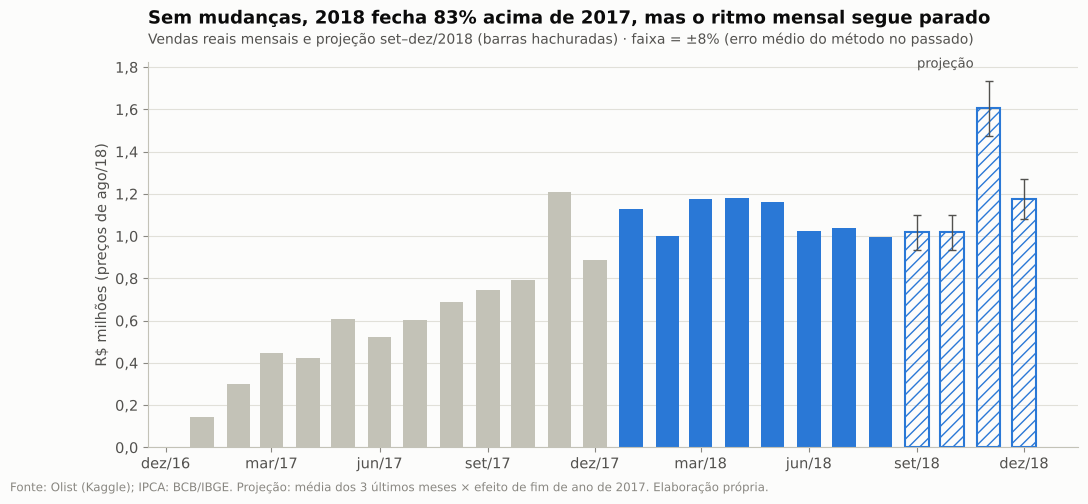

In [5]:
# ============================================================
# GRÁFICO: VENDAS REAIS MENSAIS E PROJEÇÃO SET–DEZ/2018
# ============================================================

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(mensal.index, mensal / 1e6, width=20,
       color=[viz.DESTAQUE if d.year == 2018 else viz.CONTEXTO for d in mensal.index])
ax.bar(proj.index, proj / 1e6, width=20, color="none", edgecolor=viz.DESTAQUE, linewidth=1.5, hatch="///")
ax.errorbar(proj.index, proj / 1e6, yerr=proj / 1e6 * erro_medio, fmt="none",
            ecolor=viz.TINTA_SECUNDARIA, capsize=3, lw=1)
ax.text(proj.index[0], proj.max() / 1e6 * 1.12, "projeção", fontsize=9.5, color=viz.TINTA_SECUNDARIA)
ax.yaxis.set_major_locator(mtick.MultipleLocator(0.2))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: br(v, 1)))
ax.set_ylabel("R\\$ milhões (preços de ago/18)")
viz.eixo_mensal(ax)
crescimento = 100 * (ano_2018 / ano_2017 - 1)
viz.titulo(ax, f"Sem mudanças, 2018 fecha {br(crescimento)}% acima de 2017, mas o ritmo mensal segue parado",
           f"Vendas reais mensais e projeção set–dez/2018 (barras hachuradas) · faixa = ±{br(100 * erro_medio)}% "
           f"(erro médio do método no passado)")
viz.fonte(fig, "Fonte: Olist (Kaggle); IPCA: BCB/IBGE. Projeção: média dos 3 últimos meses × efeito de fim de ano de 2017. "
               "Elaboração própria.")
viz.salvar_figura(fig, "05_projecao")
plt.show()

**Leitura (P1 e P2):**

| Medida | Resultado |
|---|---|
| Erro do método no passado | Entre 3,8% e 14,7% por mês; **8,1% em média** (o maior erro foi em jun/18, quando a receita caiu) |
| Nível atual | R$ 1,02 mi por mês (média de jun–ago/18) |
| Efeito de fim de ano em 2017 | Novembro 1,57x e dezembro 1,15x a média de set–out |
| Vendas reais 2017 | R$ 7,37 mi |
| Vendas reais 2018 projetadas | **R$ 13,53 mi** (faixa de R$ 13,14 a 13,92 mi), **+83%** sobre 2017 |
| Ritmo de saída do ano | **6,3% abaixo** da média de 2018 até agosto |

- O +83% é **herança de 2017**: o ano anterior começou pequeno e cresceu mês a mês, enquanto 2018 já começa no patamar alto. A comparação anual infla o crescimento.
- O sinal que importa é o **ritmo mensal**: em 2018 a receita oscila entre R$ 1,0 e 1,2 mi por mês, sem tendência de alta, e caiu a partir de junho.
- **Limitação:** o efeito de fim de ano vem de 2017, quando a empresa ainda crescia rápido; por isso a projeção de novembro e dezembro pode estar otimista. O número deve ser lido como cenário, não como meta.

**Conclusão (P1):** se nada mudar, 2018 fecha bem acima de 2017 no total, mas entra em 2019 parado. A retomada do crescimento depende das alavancas avaliadas nas próximas seções.

## 3. Quanto vale cada alavanca (P3)
Esta é a parte **prescritiva**: simulações de cenário. Cada cenário usa taxas observadas nos próprios dados e uma premissa explícita; os resultados são ordens de grandeza para priorizar, não promessas. Há dois tipos de ganho: **experiência** (avaliações ruins evitadas) e **receita** (vendas adicionais por ano).

| Cenário | Premissa | De onde vem |
|---|---|---|
| A. Atraso pela metade | Metade dos pedidos atrasados passa a ter a taxa de notas ruins de quem recebe no prazo | Ato 2 |
| B. Entrega completa | Pedidos com 2 ou mais itens entregues no prazo passam a ter a taxa dos pedidos de 1 item | Ato 2 |
| C. Norte e Nordeste | As duas regiões atingem a penetração do Centro-Oeste (pedidos por 100 mil habitantes), com o ticket regional atual | Ato 1 |
| D. +1 ponto de recompra | Clientes novos por ano × 1 ponto percentual a mais de recompra × ticket médio | Ato 3 |

No cenário C, a comparação entre regiões é feita **por habitante**, e não pelo total de pedidos, pelo mesmo motivo da sinistralidade na Aula 2 de Fundamentos: volume bruto não é desempenho quando os grupos têm tamanhos diferentes.

In [6]:
# ============================================================
# CENÁRIOS DE EXPERIÊNCIA: AVALIAÇÕES RUINS EVITADAS (A E B)
# ============================================================

ent = pedidos[pedidos["na_janela"] & pedidos["entregue"] & pedidos["review_score"].notna()].copy()
ent["atrasado"] = ent["atrasado"].astype(bool)
ent["ruim"] = ent["avaliacao_ruim"].astype(bool)
n_aval = len(ent)
total_ruins = ent["ruim"].sum()
taxa_prazo = ent.loc[~ent["atrasado"], "ruim"].mean()

# A) metade dos atrasados passa a ter a taxa de nota ruim de quem chega no prazo
atrasados = ent[ent["atrasado"]]
evitadas_a = 0.5 * (atrasados["ruim"].sum() - len(atrasados) * taxa_prazo)

# B) pedidos com 2+ itens entregues no prazo passam a ter a taxa dos pedidos de 1 item no prazo
no_prazo = ent[~ent["atrasado"]]
multi = no_prazo["qtd_itens"] > 1
taxa_1_item = no_prazo.loc[~multi, "ruim"].mean()
taxa_multi = no_prazo.loc[multi, "ruim"].mean()
evitadas_b = no_prazo.loc[multi, "ruim"].sum() - multi.sum() * taxa_1_item

# A e B atingem grupos diferentes (atrasados × no prazo), então os efeitos se somam
cen_exp = pd.DataFrame({"avaliações ruins evitadas": [evitadas_a, evitadas_b, evitadas_a + evitadas_b]},
                       index=["A) Atraso pela metade", "B) Entrega completa", "A + B"])
cen_exp["redução das avaliações ruins (%)"] = 100 * cen_exp["avaliações ruins evitadas"] / total_ruins
cen_exp["% de avaliações ruins depois"] = 100 * (total_ruins - cen_exp["avaliações ruins evitadas"]) / n_aval

print(f"Pedidos entregues e avaliados: {br(n_aval)} · avaliações ruins: {br(total_ruins)} "
      f"({br(100 * total_ruins / n_aval, 1)}%)")
print(f"No prazo: 1 item = {br(100 * taxa_1_item, 1)}% de notas ruins · 2+ itens = {br(100 * taxa_multi, 1)}%")
display(cen_exp.apply(lambda col: col.map(lambda v: br(v, 1))))

,avaliações ruins evitadas,redução das avaliações ruins (%),% de avaliações ruins depois
A) Atraso pela metade,"1.695,6","13,9","11,0"
B) Entrega completa,"1.535,0","12,6","11,2"
A + B,"3.230,6","26,4","9,4"


Pedidos entregues e avaliados: 95.560 · avaliações ruins: 12.228 (12,8%)
No prazo: 1 item = 7,5% de notas ruins · 2+ itens = 24,6%


### Memorial de cálculo dos cenários A e B
Os dois cenários seguem a mesma lógica: **notas ruins que existem hoje − notas ruins que existiriam se o grupo afetado se comportasse como o grupo de referência**. A taxa de referência é o "nível normal" de insatisfação da Olist: parte dos clientes daria nota ruim de qualquer jeito (produto com defeito, expectativa diferente), e só o excesso é atribuído ao problema.

**Cenário A: atraso pela metade**

| Passo | Conta | Resultado |
|---|---|---|
| 1. Pedidos atrasados e avaliados | contagem | 6.378 |
| 2. Notas ruins entre eles | contagem | 3.981 (62,4%) |
| 3. Notas ruins esperadas se tivessem chegado no prazo | 6.378 × 9,2% (taxa de quem recebe no prazo) | ≈ 590 |
| 4. Notas ruins ligadas ao atraso | 3.981 − 590 | ≈ 3.391 |
| 5. Cenário: metade dos atrasos eliminada | 3.391 ÷ 2 | **≈ 1.696** |
| 6. Peso no total de notas ruins | 1.696 ÷ 12.228 | **≈ 14%** |

**Cenário B: entrega completa**

| Passo | Conta | Resultado |
|---|---|---|
| 1. Pedidos com 2+ itens entregues no prazo | contagem | 9.008 |
| 2. Notas ruins entre eles | contagem | 2.213 (24,6%) |
| 3. Notas ruins esperadas se fossem como pedidos de 1 item | 9.008 × 7,5% (taxa dos pedidos de 1 item no prazo) | ≈ 678 |
| 4. Notas ruins ligadas ao pedido com vários itens | 2.213 − 678 | **≈ 1.535** |
| 5. Peso no total de notas ruins | 1.535 ÷ 12.228 | **≈ 13%** |

**A + B:** 1.696 + 1.535 = **3.231** notas ruins evitadas (≈ 26%). A soma é válida porque os grupos não se sobrepõem: A atua só nos atrasados, B só nos entregues no prazo. A taxa de avaliações ruins cairia de 12.228 ÷ 95.560 = **12,8%** para (12.228 − 3.231) ÷ 95.560 = **9,4%**.

**Premissa e limite:** a conta supõe que os pedidos atrasados (ou com vários itens) seriam, fora esse problema, iguais aos de referência. Como os dados são observacionais, isso não é provado; a consistência do efeito em todas as regiões e categorias (notebook 03) sustenta a suposição. Os valores são **estimativas** para priorizar ações.

In [7]:
# ============================================================
# CENÁRIOS DE RECEITA: VENDAS ADICIONAIS POR ANO (C E D)
# ============================================================

v = pedidos[pedidos["na_janela"] & pedidos["gerou_venda"] & pedidos["gmv"].notna()]
MESES_JANELA = 20                                    # jan/2017 a ago/2018
gmv_anual = v["gmv"].sum() / MESES_JANELA * 12

# C) Norte e Nordeste com a penetração do Centro-Oeste (pedidos por 100 mil habitantes)
pop = externos.populacao_uf()
reg = v.groupby("regiao_cliente").agg(pedidos=("order_id", "count"), gmv=("gmv", "sum"))
reg = reg.join(pop.groupby("regiao")["populacao_2018"].sum())
reg["pedidos por 100 mil hab."] = reg["pedidos"] / reg["populacao_2018"] * 1e5
reg["ticket (R$)"] = reg["gmv"] / reg["pedidos"]
alvo = reg.loc["Centro-Oeste", "pedidos por 100 mil hab."]
extra_c = sum((alvo - reg.loc[r, "pedidos por 100 mil hab."]) / 1e5 * reg.loc[r, "populacao_2018"] * reg.loc[r, "ticket (R$)"]
              for r in ["Nordeste", "Norte"]) / MESES_JANELA * 12

# D) +1 ponto percentual de recompra sobre os clientes novos de um ano
novos_2018 = v[(v["ordem_compra_cliente"] == 1) & (v["mes"] >= "2018-01-01")]["customer_unique_id"].nunique()
novos_ano = novos_2018 / 8 * 12                      # 8 meses de 2018 na base, anualizados
ticket_medio = v["gmv"].mean()
extra_d = novos_ano * 0.01 * ticket_medio

display(reg[["pedidos por 100 mil hab.", "ticket (R$)"]].sort_values("pedidos por 100 mil hab.")
        .apply(lambda col: col.map(lambda x: br(x, 1))))

cen_rec = pd.DataFrame({
    "Vendas adicionais por ano (R$ mi)": [extra_c / 1e6, extra_d / 1e6],
    "% das vendas anuais atuais": [100 * extra_c / gmv_anual, 100 * extra_d / gmv_anual],
}, index=["C) Norte e Nordeste na penetração do Centro-Oeste", "D) +1 ponto de recompra"])
print(f"Vendas anualizadas de referência: R$ {br(gmv_anual / 1e6, 2)} mi · "
      f"clientes novos por ano: {br(novos_ano)} · ticket médio: R$ {br(ticket_medio, 2)}")
display(cen_rec.apply(lambda col: col.map(lambda x: br(x, 2))))

,pedidos por 100 mil hab.,ticket (R$)
regiao_cliente,,
Norte,"10,1","223,3"
Nordeste,"16,3","201,2"
Centro-Oeste,"35,5","177,0"
Sul,"46,9","162,8"
Sudeste,"76,6","150,8"


,Vendas adicionais por ano (R$ mi),% das vendas anuais atuais
C) Norte e Nordeste na penetração do Centro-Oeste,"1,93","20,55"
D) +1 ponto de recompra,"0,12","1,32"


Vendas anualizadas de referência: R$ 9,41 mi · clientes novos por ano: 77.468 · ticket médio: R$ 160,19


### Memorial de cálculo dos cenários C e D
No lado da receita a lógica é **pedidos a mais × valor de cada pedido**, convertido para um ano. A régua são as vendas anuais de hoje: R$ 15,68 mi em 20 meses ÷ 20 × 12 ≈ **R$ 9,41 mi por ano**.

**Cenário C: Norte e Nordeste na penetração do Centro-Oeste**

| Passo | Nordeste | Norte |
|---|---|---|
| 1. Pedidos na janela (20 meses) | 9.272 | 1.828 |
| 2. População 2018 (IBGE) | 56,8 mi | 18,2 mi |
| 3. Penetração (pedidos por 100 mil hab.) | 16,3 | 10,1 |
| 4. Meta: penetração do Centro-Oeste | 35,5 | 35,5 |
| 5. Pedidos que faltam = (35,5 − penetração) ÷ 100 mil × população | ≈ 10.883 | ≈ 4.628 |
| 6. × ticket médio da própria região | × R$ 201,17 | × R$ 223,32 |
| 7. Vendas a mais em 20 meses | ≈ R$ 2,19 mi | ≈ R$ 1,03 mi |

Total em 20 meses ≈ R$ 3,22 mi → ÷ 20 × 12 = **≈ R$ 1,93 mi por ano**, ou 1,93 ÷ 9,41 ≈ **20,6% das vendas**. A comparação é por habitante, e não pelo total de pedidos, porque as regiões têm tamanhos diferentes (mesma lógica da sinistralidade na Aula 2 de Fundamentos). A meta é conservadora: o Sudeste tem 76,6 pedidos por 100 mil.

**Cenário D: +1 ponto de recompra**

| Passo | Conta | Resultado |
|---|---|---|
| 1. Clientes novos por ano | 51.645 em jan–ago/2018 ÷ 8 × 12 | ≈ 77.468 |
| 2. Clientes que voltariam a mais | 77.468 × 1% | ≈ 775 |
| 3. Vendas a mais por ano | 775 × R$ 160,19 (ticket médio) | **≈ R$ 0,12 mi** |
| 4. Peso nas vendas anuais | 0,12 ÷ 9,41 | **≈ 1,3%** |

**Por que C é tão maior que D:** C mexe em mais de 15 mil pedidos de regiões pouco exploradas; D mexe em cerca de 775, porque 1 ponto de recompra é pouco sobre uma base que recompra só 1,9%.

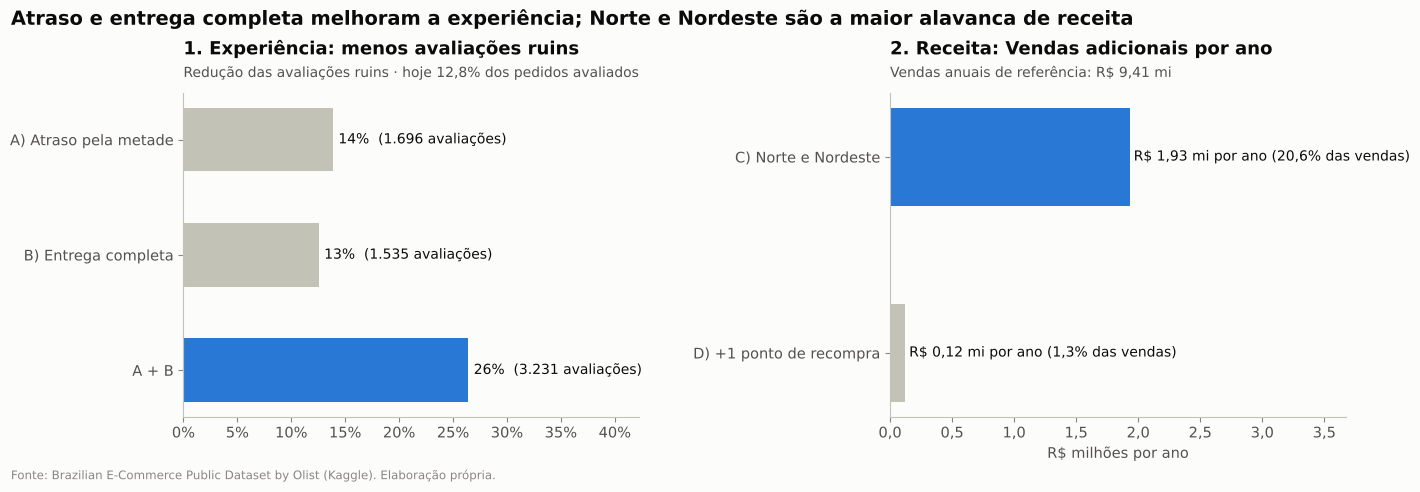

In [8]:
# ============================================================
# GRÁFICO: QUANTO VALE CADA ALAVANCA
# ============================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"wspace": 0.55})

# painel 1: experiência
red = cen_exp["redução das avaliações ruins (%)"]
cores = [viz.CONTEXTO, viz.CONTEXTO, viz.DESTAQUE]
ax1.barh(red.index[::-1], red.values[::-1], color=cores[::-1], height=0.55)
for i, (val, n) in enumerate(zip(red.values[::-1], cen_exp["avaliações ruins evitadas"].values[::-1])):
    ax1.text(val + 0.5, i, f"{br(val)}%  ({br(n)} avaliações)", va="center", fontsize=10)
ax1.set_xlim(0, red.max() * 1.6)
ax1.xaxis.set_major_formatter(viz.formato_pct())
ax1.grid(axis="y", visible=False)
viz.titulo(ax1, "1. Experiência: menos avaliações ruins",
           f"Redução das avaliações ruins · hoje {br(100 * total_ruins / n_aval, 1)}% dos pedidos avaliados")

# painel 2: receita
ganho = cen_rec["Vendas adicionais por ano (R$ mi)"]
rotulos = ["C) Norte e Nordeste", "D) +1 ponto de recompra"]
ax2.barh(rotulos[::-1], ganho.values[::-1], color=[viz.CONTEXTO, viz.DESTAQUE], height=0.5)
for i, (val, pct) in enumerate(zip(ganho.values[::-1], cen_rec["% das vendas anuais atuais"].values[::-1])):
    ax2.text(val + 0.03, i, f"R\\$ {br(val, 2)} mi por ano ({br(pct, 1)}% das vendas)", va="center", fontsize=10)
ax2.set_xlim(0, ganho.max() * 1.9)
ax2.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: br(x, 1)))
ax2.set_xlabel("R\\$ milhões por ano")
ax2.grid(axis="y", visible=False)
viz.titulo(ax2, "2. Receita: Vendas adicionais por ano",
           f"Vendas anuais de referência: R\\$ {br(gmv_anual / 1e6, 2)} mi")

fig.suptitle("Atraso e entrega completa melhoram a experiência; Norte e Nordeste são a maior alavanca de receita",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.08)
viz.fonte(fig)
viz.salvar_figura(fig, "05_alavancas")
plt.show()

**Leitura (P3):**

| Cenário | Ganho | Leitura |
|---|---|---|
| A) Atraso pela metade | **14%** menos avaliações ruins (cerca de 1.700) | Maior efeito por pedido, com causas já identificadas (picos, regiões, vendedores) |
| B) Entrega completa | **13%** menos avaliações ruins (cerca de 1.500) | Ataca a insatisfação que o atraso não explica: pedidos com 2+ itens têm 24,6% de notas ruins no prazo, contra 7,5% com 1 item |
| A + B | A taxa de avaliações ruins cairia de **12,8% para 9,4%** | Os efeitos se somam, porque atingem pedidos diferentes |
| C) Norte e Nordeste | **R$ 1,93 mi por ano, cerca de 21% das vendas** | **Maior alavanca de receita**, e o alvo ainda é conservador: o Centro-Oeste tem menos da metade da penetração do Sudeste |
| D) +1 ponto de recompra | R$ 0,12 mi por ano, cerca de 1,3% das vendas | Pequeno no curto prazo, mas é receita sem custo de aquisição e cresce com a base de clientes |

- **Experiência e receita estão ligadas:** o ganho direto de receita de A e B é pequeno, porque o cliente insatisfeito recompra só 21% menos sobre uma base de 2%. Mas eles protegem a reputação e são **pré-condição de C**: crescer no Norte e Nordeste exige resolver prazo e frete na região (Ato 2).
- **D depende de prova:** o Ato 3 mostrou que a nota não explica a recompra baixa. Antes de investir em retenção, é preciso testar se uma ação de fato traz o cliente de volta, o que a seção 4 desenha.

**Conclusão (P3):** a ordem de prioridade é **logística primeiro** (A, B e a base para C), **expansão regional** em seguida (C) e **retenção validada por piloto** (D).

## 4. Provar antes de escalar: desenho do piloto de 2ª compra (P4 e P5)
Todos os achados até aqui são **observacionais**: mostram associações, e correlação não prova causa (Aula 1 de Estatística). Antes de investir em um programa de retenção em escala, a recomendação da Aula 1 de Fundamentos é **começar pequeno**: um piloto controlado, que mede o impacto e só depois escala.

| Elemento | Definição |
|---|---|
| População-alvo | Clientes novos, logo após a entrega da 1ª compra; prioridade aos de **alto valor** (1ª compra acima do corte dos 20% que mais gastam, como no RFM do notebook 04) |
| Grupos | **Ação** (recebe o convite para a 2ª compra, como cupom e e-mail) × **controle** (não recebe nada) |
| Sorteio | Aleatório **estratificado** pelo tipo de categoria da 1ª compra (reposição × demais), para os dois grupos terem a mesma mistura (Aula 3 de Estatística) |
| KPI | Taxa de recompra em até 180 dias, com a mesma regra do notebook 04 |
| Hipótese | A recompra sobe de cerca de 1,9% para 3,0% no grupo de ação |
| Critérios | 95% de confiança (Z = 1,96) e 80% de poder (Z = 0,84) |

O tamanho de cada grupo vem da fórmula de comparação entre **duas proporções** da Aula 3 de Estatística:

$$n = \frac{\left[Z_{\alpha}\sqrt{2\,\bar{p}(1-\bar{p})} + Z_{\beta}\sqrt{p_1(1-p_1) + p_2(1-p_2)}\right]^2}{(p_1 - p_2)^2}$$

em que $p_1$ é a taxa atual, $p_2$ é a taxa esperada com a ação e $\bar{p}$ é a média das duas.

In [9]:
# ============================================================
# PILOTO DA 2ª COMPRA: TAMANHO DA AMOSTRA (P4 E P5)
# ============================================================

# linha de base: recompra em até 180 dias, com a mesma regra do notebook 04
vendas_c = (pedidos[pedidos["gerou_venda"] & pedidos["gmv"].notna()]
            .sort_values("order_purchase_timestamp").copy())
vendas_c["n_compra"] = vendas_c.groupby("customer_unique_id").cumcount() + 1
primeira = vendas_c[vendas_c["n_compra"] == 1].set_index("customer_unique_id")
segunda = vendas_c[vendas_c["n_compra"] == 2].set_index("customer_unique_id")["order_purchase_timestamp"]
dias_2a = (segunda - primeira.loc[segunda.index, "order_purchase_timestamp"]).dt.total_seconds() / 86400
coorte = primeira[(primeira["order_purchase_timestamp"] >= "2017-01-01") &
                  (primeira["order_purchase_timestamp"] < "2018-03-01")].copy()
coorte["recompra"] = dias_2a.reindex(coorte.index).between(1, 180)
p_base = coorte["recompra"].mean()


def tamanho_amostra(p1, p2, z_alfa=1.96, z_beta=0.84):
    """Clientes por grupo para comparar duas proporções (Aula 3 de Estatística)."""
    p_medio = (p1 + p2) / 2
    termo = (z_alfa * math.sqrt(2 * p_medio * (1 - p_medio))
             + z_beta * math.sqrt(p1 * (1 - p1) + p2 * (1 - p2)))
    return math.ceil(termo ** 2 / (p1 - p2) ** 2)


# fluxo mensal de clientes novos em 2018 e corte de alto valor (20% que mais gastam, como no RFM)
corte_alto = vendas_c[vendas_c["na_janela"]].groupby("customer_unique_id")["gmv"].sum().quantile(0.8)
novos = primeira[(primeira["mes"] >= "2018-01-01") & (primeira["mes"] <= "2018-08-01")]
fluxo_todos = novos.groupby("mes").size().mean()
fluxo_alto = novos[novos["gmv"] >= corte_alto].groupby("mes").size().mean()

alvos = [0.025, 0.030, 0.035, 0.040]
plano = pd.DataFrame({
    "aumento (pontos percentuais)": [100 * (a - p_base) for a in alvos],
    "clientes por grupo": [tamanho_amostra(p_base, a) for a in alvos],
}, index=[f"{br(100 * p_base, 1)}% → {br(100 * a, 1)}%" for a in alvos])
plano.index.name = "recompra: hoje → com a ação"
plano["total do teste"] = 2 * plano["clientes por grupo"]
plano["meses (todos os novos)"] = plano["total do teste"] / fluxo_todos
plano["meses (só alto valor)"] = plano["total do teste"] / fluxo_alto

print(f"Recompra em 180 dias hoje: {br(100 * p_base, 2)}% ({br(len(coorte))} clientes acompanhados)")
print(f"Corte de alto valor: R$ {br(corte_alto, 2)}")
print(f"Clientes novos por mês em 2018: {br(fluxo_todos)} · com 1ª compra de alto valor: {br(fluxo_alto)}")
display(plano.assign(**{
    "aumento (pontos percentuais)": plano["aumento (pontos percentuais)"].map(lambda x: br(x, 1)),
    "clientes por grupo": plano["clientes por grupo"].map(br),
    "total do teste": plano["total do teste"].map(br),
    "meses (todos os novos)": plano["meses (todos os novos)"].map(lambda x: br(x, 1)),
    "meses (só alto valor)": plano["meses (só alto valor)"].map(lambda x: br(x, 1)),
}))

,aumento (pontos percentuais),clientes por grupo,total do teste,meses (todos os novos),meses (só alto valor)
recompra: hoje → com a ação,,,,,
"1,9% → 2,5%","0,6",9.236,18.472,"2,9","15,2"
"1,9% → 3,0%","1,1",3.071,6.142,"1,0","5,1"
"1,9% → 3,5%","1,6",1.599,3.198,"0,5","2,6"
"1,9% → 4,0%","2,1",1.013,2.026,"0,3","1,7"


Recompra em 180 dias hoje: 1,90% (56.332 clientes acompanhados)
Corte de alto valor: R$ 208,97
Clientes novos por mês em 2018: 6.458 · com 1ª compra de alto valor: 1.214


### Memorial de cálculo do tamanho da amostra
**Números-base (prints acima):**
- **Recompra hoje (p₁ = 1,90%):** dos 56.332 clientes com 1ª compra entre jan/2017 e fev/2018, 1.068 voltaram entre o dia 1 e o dia 180 → 1.068 ÷ 56.332 = 1,90%. Em linguagem simples: de cada 100 clientes novos, só 2 voltam em 6 meses.
- **Corte de alto valor (R$ 208,97):** o gasto de cada cliente na janela é ordenado e o corte é o valor que separa os 20% que mais gastam (percentil 80), como no RFM do notebook 04.

**Coluna a coluna, para a meta de 3,0%:**

| Coluna | Conta | Resultado |
|---|---|---|
| Aumento | 3,0% − 1,9% | 1,1 ponto |
| Clientes por grupo | fórmula de duas proporções (abaixo) | **3.071** |
| Total do teste | 3.071 × 2 grupos (ação e controle) | 6.142 |
| Meses (todos os novos) | 6.142 ÷ 6.458 clientes novos por mês | ≈ 1,0 |
| Meses (só alto valor) | 6.142 ÷ 1.214 clientes novos de alto valor por mês | ≈ 5,1 |

**A fórmula, passo a passo**

Para facilitar a conta à mão, as taxas foram arredondadas: $p_1 = 0{,}019$ (recompra hoje, 1,9%), $p_2 = 0{,}030$ (meta com a ação, 3,0%), $Z_\alpha = 1{,}96$ (95% de confiança) e $Z_\beta = 0{,}84$ (80% de poder).

| Passo | O que se calcula | Conta | Resultado |
|---|---|---|---|
| P1 | Média das duas taxas ($\bar{p}$) | (0,019 + 0,030) ÷ 2 | 0,0245 |
| P2 | Parte da **confiança** | 1,96 × √(2 × 0,0245 × 0,9755) = 1,96 × √0,04780 = 1,96 × 0,2186 | 0,4285 |
| P3 | Parte do **poder** | 0,84 × √(0,019 × 0,981 + 0,030 × 0,970) = 0,84 × √(0,01864 + 0,02910) = 0,84 × 0,2185 | 0,1835 |
| P4 | Numerador: soma ao quadrado (o **ruído**) | (0,4285 + 0,1835)² = 0,6120² | 0,3746 |
| P5 | Denominador: diferença ao quadrado (o **sinal**) | (0,030 − 0,019)² = 0,011² | 0,000121 |
| P6 | Clientes por grupo | 0,3746 ÷ 0,000121 | ≈ 3.096 ≈ **3.100** |
| P7 | Total do teste (× 2: grupo de ação + grupo de controle) | 3.071 × 2 | **6.142** |

- **Por que o código dá 3.071 e a conta dá 3.096:** o código usa a taxa exata ($p_1$ = 1,8959%), e não 1,9%. A diferença vem só do arredondamento.
- **Como ler a fórmula:** em cima fica o **ruído** (a variação natural das taxas, que cresce com a confiança e o poder exigidos); embaixo fica o **sinal** (o tamanho do efeito que se quer enxergar). Quanto menor o sinal, mais clientes são necessários para separá-lo do ruído.
- **Por que multiplicar por 2:** a fórmula dá o tamanho de **cada** grupo. O teste precisa de dois grupos do mesmo tamanho: o de ação (recebe o convite) e o de controle (não recebe nada).

**O que significam os critérios:** 95% de confiança = só 5% de chance de "ver" um efeito que não existe; 80% de poder = 80% de chance de enxergar o efeito, se ele existir.

As outras linhas repetem a mesma conta, mudando só a meta. Quanto menor o aumento, menor o divisor do passo 5 e maior o teste (2,5% → 9.236 por grupo). Os meses mostram só o tempo para **formar** os grupos; o resultado sai 180 dias depois.

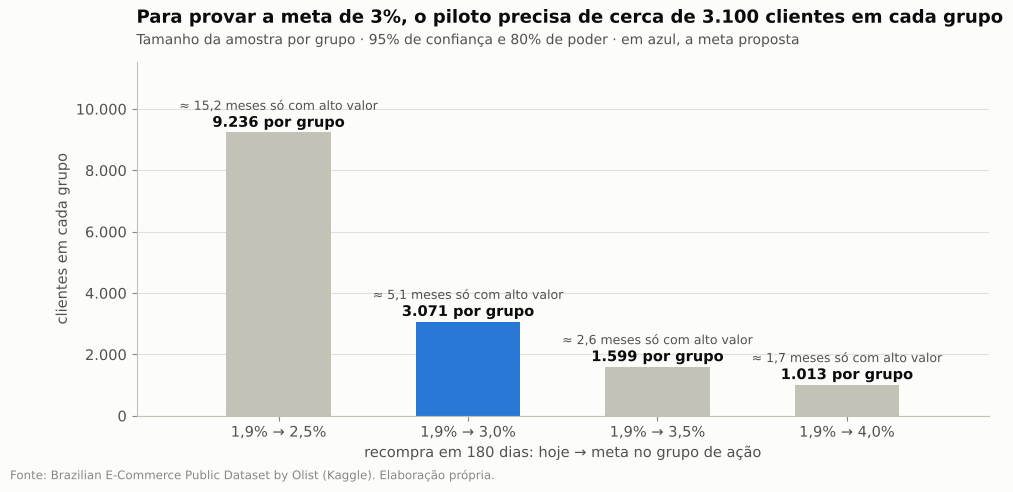

In [10]:
# ============================================================
# GRÁFICO: QUANTO MENOR O EFEITO, MAIOR O TESTE
# ============================================================

fig, ax = plt.subplots(figsize=(11, 4.6))
cores = [viz.DESTAQUE if abs(a - 0.03) < 1e-9 else viz.CONTEXTO for a in alvos]
ax.bar(plano.index, plano["clientes por grupo"], color=cores, width=0.55)
for i, (n, meses) in enumerate(zip(plano["clientes por grupo"], plano["meses (só alto valor)"])):
    topo = plano["clientes por grupo"].max()
    ax.text(i, n + 0.02 * topo, f"{br(n)} por grupo", ha="center", fontsize=10.5, weight="bold", color=viz.TINTA)
    ax.text(i, n + 0.08 * topo, f"≈ {br(meses, 1)} meses só com alto valor", ha="center", fontsize=9,
            color=viz.TINTA_SECUNDARIA)
ax.set_ylim(0, plano["clientes por grupo"].max() * 1.25)
ax.set_xlim(-0.75, len(alvos) - 0.25)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: br(x)))
ax.set_xlabel("recompra em 180 dias: hoje → meta no grupo de ação")
ax.set_ylabel("clientes em cada grupo")
ax.grid(axis="x", visible=False)
viz.titulo(ax, "Para provar a meta de 3%, o piloto precisa de cerca de 3.100 clientes em cada grupo",
           "Tamanho da amostra por grupo · 95% de confiança e 80% de poder · em azul, a meta proposta")
viz.fonte(fig)
viz.salvar_figura(fig, "05_piloto_amostra")
plt.show()

### Recap: como foram definidas as categorias de reposição
O sorteio separa os clientes em duas "pilhas" (estratos) pela categoria da 1ª compra: **reposição** e **demais**. Para o leitor não precisar voltar ao notebook 04, o critério é refeito aqui com a mesma base do piloto.

| Etapa | O que foi feito | Resultado |
|---|---|---|
| 1. Origem | Hipótese H7 do notebook 04: o tipo de produto da 1ª compra muda a chance de voltar? | Recompra em 180 dias por categoria da 1ª compra |
| 2. Base | Clientes com 1ª compra entre jan/2017 e fev/2018 (a mesma coorte do piloto) | 56.332 clientes; recompra média de **1,90%** |
| 3. Filtro | Só categorias com **500 clientes ou mais** | Evita taxas instáveis: com poucos clientes, uma recompra a mais muda muito a porcentagem |
| 4. Ordenação | Categorias da maior para a menor recompra | Tabela abaixo |
| 5. Corte | As **5 primeiras** formam o estrato "reposição" | Todas com recompra de 2,34% ou mais, pelo menos **23% acima da média**; a 6ª (ferramentas jardim, 2,02%) já fica só 6% acima |

- **Por que o nome "reposição":** é um rótulo do estudo para as categorias em que o cliente mais volta, como pet shop (itens de uso contínuo). Nem todas são de reposição no sentido literal: móveis decoração, por exemplo, entra pelo dado, e não pela natureza do produto.
- **Ressalva:** o corte em 5 é uma escolha do estudo, apoiada no degrau entre a 5ª categoria (+23%) e a 6ª (+6%). Outro corte mudaria a proporção de cada pilha, mas não a lógica do sorteio estratificado.

In [11]:
# ============================================================
# RECAP: COMO AS CATEGORIAS DE REPOSIÇÃO FORAM DEFINIDAS (NOTEBOOK 04, H7)
# ============================================================

# recompra em 180 dias por categoria da 1ª compra, só com categorias de 500+ clientes
por_categoria = coorte.groupby("categoria_principal")["recompra"].agg(clientes="count", taxa="mean")
por_categoria = por_categoria[por_categoria["clientes"] >= 500].sort_values("taxa", ascending=False)
por_categoria["taxa"] = 100 * por_categoria["taxa"]
por_categoria["acima da média (%)"] = 100 * (por_categoria["taxa"] / (100 * p_base) - 1)

# as 5 categorias de maior recompra formam o estrato "reposição"
REPOSICAO = list(por_categoria.head(5).index)
por_categoria["estrato no sorteio"] = np.where(por_categoria.index.isin(REPOSICAO), "reposição", "demais")

print(f"Média geral de recompra em 180 dias: {br(100 * p_base, 2)}%")
print(f"Categorias de reposição (5 de maior recompra): {', '.join(REPOSICAO)}")
display(por_categoria.assign(
    clientes=por_categoria["clientes"].map(br),
    taxa=por_categoria["taxa"].map(lambda x: br(x, 2) + "%"),
    **{"acima da média (%)": por_categoria["acima da média (%)"].map(lambda x: f"{sinal(x)}{br(x)}%")},
).rename(columns={"taxa": "recompra em 180 dias"}))

,clientes,recompra em 180 dias,acima da média (%),estrato no sorteio
categoria_principal,,,,
pet shop,828,"2,90%",+53%,reposição
fashion bolsas e acessorios,1.157,"2,85%",+50%,reposição
esporte lazer,4.569,"2,58%",+36%,reposição
cama mesa banho,5.440,"2,46%",+30%,reposição
moveis decoracao,3.759,"2,34%",+23%,reposição
ferramentas jardim,2.332,"2,02%",+6%,demais
perfumaria,1.989,"2,01%",+6%,demais
bebes,1.512,"1,92%",+1%,demais
beleza saude,4.387,"1,89%",-0%,demais


Média geral de recompra em 180 dias: 1,90%
Categorias de reposição (5 de maior recompra): pet shop, fashion bolsas e acessorios, esporte lazer, cama mesa banho, moveis decoracao


In [12]:
# ============================================================
# SIMULAÇÃO DO SORTEIO ESTRATIFICADO (CLIENTES NOVOS DE JUL–AGO/2018)
# ============================================================
# REPOSICAO foi definida na célula anterior (5 categorias de maior recompra)

simulacao = novos[novos["mes"] >= "2018-07-01"].copy()
simulacao["estrato"] = np.where(simulacao["categoria_principal"].isin(REPOSICAO), "reposição", "demais categorias")

# metade de cada estrato vai para o grupo de ação, por sorteio
acao = simulacao.groupby("estrato", group_keys=False).sample(frac=0.5, random_state=SEMENTE)
simulacao["grupo"] = np.where(simulacao.index.isin(acao.index), "ação", "controle")

n_total = len(simulacao)
n_rep = int((simulacao["estrato"] == "reposição").sum())
print(f"Clientes novos de jul–ago/2018: {br(n_total)} · reposição: {br(n_rep)} ({br(100 * n_rep / n_total, 1)}%) · "
      f"demais: {br(n_total - n_rep)} ({br(100 * (n_total - n_rep) / n_total, 1)}%)")
print(f"Cada grupo recebe metade de cada pilha: {br(n_rep / 2)} de reposição + {br((n_total - n_rep) / 2)} das demais "
      f"= {br(n_total / 2)} clientes")

balanco = pd.crosstab(simulacao["grupo"], simulacao["estrato"], normalize="index") * 100
balanco["clientes"] = simulacao["grupo"].value_counts()
balanco["ticket médio da 1ª compra (R$)"] = simulacao.groupby("grupo")["gmv"].mean()
display(balanco.apply(lambda col: col.map(lambda x: br(x, 0 if col.name == "clientes" else 1))))

estrato,demais categorias,reposição,clientes,ticket médio da 1ª compra (R$)
grupo,,,,
ação,"75,9","24,1",6.113,"163,8"
controle,"75,9","24,1",6.113,"158,9"


Clientes novos de jul–ago/2018: 12.226 · reposição: 2.950 (24,1%) · demais: 9.276 (75,9%)
Cada grupo recebe metade de cada pilha: 1.475 de reposição + 4.638 das demais = 6.113 clientes


In [13]:
# ============================================================
# EXEMPLOS: QUEM CAIU EM CADA GRUPO NO SORTEIO
# ============================================================

exemplos = (simulacao[["estrato", "categoria_principal", "gmv", "grupo"]]
            .groupby("grupo", group_keys=False)
            .head(5)                                   # 5 clientes de cada grupo
            .rename(columns={"categoria_principal": "categoria da 1ª compra",
                             "gmv": "valor da 1ª compra (R$)"}))
exemplos["valor da 1ª compra (R$)"] = exemplos["valor da 1ª compra (R$)"].map(lambda x: br(x, 2))
display(exemplos.sort_values("grupo"))

,estrato,categoria da 1ª compra,valor da 1ª compra (R$),grupo
customer_unique_id,,,,
16e1cfa8f090f7b765fb08945e38e9d6,demais categorias,eletronicos,"18,87",ação
079ec2c879df176aab74e81e61a12f50,demais categorias,informatica acessorios,"17,38",ação
561e48624eb8366b9253ad9807c19fb6,reposição,moveis decoracao,"315,02",ação
805922a35a678927e40dac9c79a1971c,demais categorias,utilidades domesticas,"448,91",ação
bca9d4bbd28dea71c49b8d5422bc83bd,reposição,fashion bolsas e acessorios,"52,83",ação
518614d35d240f297c3e88ae861f08e5,demais categorias,moveis sala,"132,17",controle
4fc947b98e39aa4adf055a99dd82fe13,demais categorias,ferramentas jardim,"182,46",controle
c26acf4e43730d37eca795bcd809b8ab,demais categorias,informatica acessorios,"45,03",controle
5069b600e117a95d45266d2c8a4bb225,demais categorias,bebes,"58,28",controle


**Leitura do sorteio, passo a passo:**

| Pergunta | Resultado | Interpretação |
|---|---|---|
| Quem entrou na simulação? | Os 12.226 clientes novos de jul–ago/2018 | Todos os clientes novos do período, usados só para **demonstrar** o método |
| De onde vêm 24,1% e 75,9%? | 2.950 ÷ 12.226 = 24,1% (reposição) · 9.276 ÷ 12.226 = 75,9% (demais) | É a proporção natural de cada pilha na base, não uma escolha |
| Como cada grupo foi formado? | Metade de cada pilha: 2.950 ÷ 2 = 1.475 e 9.276 ÷ 2 = 4.638 → 1.475 + 4.638 = **6.113** por grupo | Como cada pilha é dividida ao meio, os dois grupos herdam a mesma mistura (24,1% e 75,9%) |
| Por que 6.113, e não 3.071? | A simulação usou todos os clientes do período | 3.071 por grupo é o **mínimo** dado pela fórmula; no piloto real, sorteia-se esse número. A simulação só mostra que o sorteio equilibra os grupos |
| Por que o ticket médio difere? | Valor médio da 1ª compra: R\$ 163,8 (ação) × R\$ 158,9 (controle), diferença de cerca de 3% | O sorteio equilibrou só a **categoria**; o valor ficou por conta do acaso. A diferença é pequena; se o valor fosse decisivo, seria possível estratificar também por faixa de valor |
| Quem recebe a ação? | Só o grupo de ação recebe o convite (cupom e e-mail); o controle segue normalmente | Depois de 180 dias, compara-se a recompra dos dois grupos: a diferença mede o efeito da ação |

**Leitura (P4 e P5):**

| Medida | Resultado |
|---|---|
| Recompra em 180 dias hoje | 1,90% (56.332 clientes acompanhados) |
| Clientes por grupo para provar **1,9% → 3,0%** | **cerca de 3.100**, ou 6.100 no total |
| Clientes novos por mês em 2018 | cerca de 6.460, dos quais 1.210 com 1ª compra de alto valor (R$ 208,97 ou mais) |
| Tempo para formar a amostra | **1 mês** com todos os clientes novos; **cerca de 5 meses** só com os de alto valor |
| Resultado do piloto | Depois de formada a amostra, mais **180 dias** de acompanhamento |

- **Quanto menor o efeito, maior o teste:** para provar um aumento menor (1,9% para 2,5%), seriam cerca de 9.200 clientes por grupo; para 4,0%, cerca de 1.000.
- **O sorteio estratificado funciona:** na simulação com os clientes novos de jul–ago/2018, os dois grupos ficaram com a mesma proporção de categorias de reposição (24,1%) e ticket parecido (diferença de cerca de 3%, fruto do acaso). A diferença que aparecer depois de 180 dias poderá ser atribuída à ação, e não à mistura de clientes.
- **Por que não usar só clientes de alto valor desde o início:** o teste ficaria cinco vezes mais lento. Uma alternativa é sortear entre todos os novos e analisar o grupo de alto valor à parte.

**Conclusão (P4 e P5):** o piloto é barato e rápido de montar: cerca de 6.100 clientes, formados em 1 a 5 meses, com resultado em menos de um ano. Se a recompra do grupo de ação chegar a 3%, o programa é escalado; se não, a Olist economiza o investimento.

## 5. Regressão linear passo a passo: prever a nota ruim pelo atraso e pelo nº de itens (P6)
**Pergunta (P6):** dá para saber, no dia da entrega, quais pedidos têm mais risco de receber nota ruim?

**A ideia em uma frase:** calcular uma equação com os pedidos do passado (**treino**), conferir se ela acerta em pedidos que ela nunca viu (**teste**) e usá-la para montar a fila do atendimento.

**A equação que será calculada:**

$$y = a + b_1 \cdot x_1 + b_2 \cdot x_2$$

| Símbolo | O que é | Valores possíveis |
|---|---|---|
| **y** | % de pedidos com nota ruim (nota 1 ou 2) | de 0% a 100% |
| **x1** | dias de atraso na entrega | 0 = no prazo · 1, 2, ..., 6 · 7 = 7 dias ou mais |
| **x2** | itens extras no pedido | 0 = 1 item · 1 = 2 itens · 2 = 3 itens ou mais |
| **a** | ponto de partida: pedido no prazo e com 1 item | calculado no treino |
| **b1** | quanto y sobe a cada dia de atraso | calculado no treino |
| **b2** | quanto y sobe a cada item extra | calculado no treino |

**Por que essas duas variáveis:** são os dois achados do Ato 2 (notebook 03): o atraso derruba a nota, e o pedido com vários itens tem mais notas ruins mesmo quando chega no prazo. As duas são conhecidas no dia da entrega.

**Critério de aprovação adotado:** a equação só é aceita se o **R² for de 0,70 ou mais no treino e no teste**.

**Roteiro:**

| Passo | O que é feito | O que sai | Fase do CRISP-DM |
|---|---|---|---|
| 1 | Separar os pedidos em treino (jan/2017 a mar/2018) e teste (abr a ago/2018) | duas bases | 2 · Entendimento dos dados |
| 2 | Transformar cada pedido em x1, x2 e y | três colunas | 3 · Preparação |
| 3 | Resumir o treino em grupos de pedidos iguais | tabela de 24 grupos | 3 · Preparação |
| 4 | Medir a correlação de x1 e de x2 com y | r de cada variável | 2 · Entendimento dos dados |
| 5 | Calcular a equação com o treino | a, b1 e b2 | 4 · Modelagem |
| 6 | Conferir a equação no próprio treino | R² do treino | 5 · Avaliação |
| 7 | Aplicar a mesma equação ao teste, sem recalcular nada | R² do teste | 5 · Avaliação |
| 8 | Projetar a nota ruim mês a mês | real × projetado | 5 · Avaliação |
| 9 | Usar a equação para montar a fila do atendimento | quem contatar | 6 · Implantação |

### Passo 1 · De onde vêm os dados: treino e teste
| | |
|---|---|
| **Entra** | a base `pedidos`, salva pelo notebook 01 |
| **É feito** | (1.1) ficam só os pedidos **entregues e avaliados**; (1.2) são criadas as colunas x1, x2 e y (detalhe no passo 2); (1.3) a base é cortada na data **01/04/2018** |
| **Sai** | `treino` (compras antes do corte) e `teste` (compras a partir do corte) |

- **Treino:** compras de jan/2017 a mar/2018. É **só com eles** que a equação é calculada.
- **Teste:** compras de abr a ago/2018. A equação **não vê** esses pedidos no cálculo; eles servem só para conferir se ela acerta.
- **Por que cortar pela data, e não sortear:** na vida real, a equação é calculada com o passado e usada no futuro. O corte pela data imita exatamente isso.

,período das compras,pedidos,notas ruins,% notas ruins,% atrasados,% com 2+ itens
TREINO (a equação é calculada aqui),jan/2017 a mar/2018,63.566,8.907,"14,0","7,8","10,0"
TESTE (a equação é conferida aqui),abr a ago/2018,31.994,3.321,"10,4","4,3","9,9"
total,jan/2017 a ago/2018,95.560,12.228,"12,8","6,7","9,9"


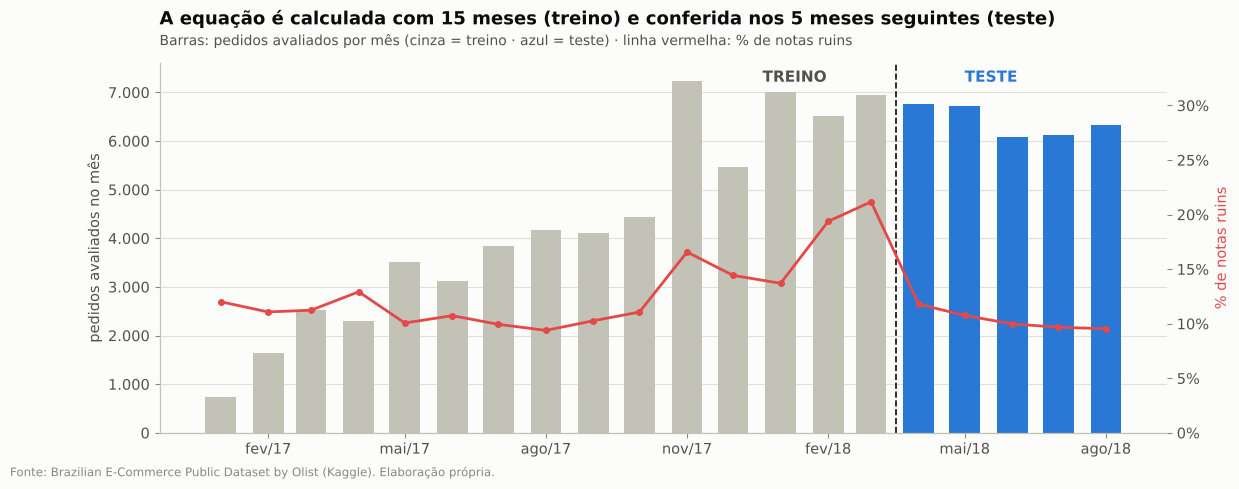

In [14]:
# ============================================================
# PASSO 1 · DE ONDE VÊM OS DADOS: BASE, TREINO E TESTE
# ============================================================

# 1.1 Base: pedidos entregues E avaliados (cada linha = 1 pedido)
base = pedidos[pedidos["na_janela"] & pedidos["entregue"] & pedidos["review_score"].notna()].copy()

# 1.2 As três colunas da regressão
base["y"] = base["avaliacao_ruim"].astype(int)                 # y  = 1 se a nota foi 1 ou 2 · 0 se foi 3, 4 ou 5
base["x1"] = base["dias_atraso"].clip(lower=0, upper=7)        # x1 = dias de atraso (0 = no prazo · 7 = 7 dias ou mais)
base["x2"] = (base["qtd_itens"] - 1).clip(lower=0, upper=2)    # x2 = itens extras (0 = 1 item · 1 = 2 itens · 2 = 3 ou mais)

# 1.3 Divisão no tempo: o treino é o passado, o teste é o "futuro"
CORTE = pd.Timestamp("2018-04-01")
treino = base[base["order_purchase_timestamp"] < CORTE].copy()     # compras de jan/2017 a mar/2018
teste = base[base["order_purchase_timestamp"] >= CORTE].copy()     # compras de abr a ago/2018

divisao = pd.DataFrame({
    "período das compras": ["jan/2017 a mar/2018", "abr a ago/2018", "jan/2017 a ago/2018"],
    "pedidos": [len(treino), len(teste), len(base)],
    "notas ruins": [treino["y"].sum(), teste["y"].sum(), base["y"].sum()],
    "% notas ruins": [100 * treino["y"].mean(), 100 * teste["y"].mean(), 100 * base["y"].mean()],
    "% atrasados": [100 * (treino["x1"] > 0).mean(), 100 * (teste["x1"] > 0).mean(), 100 * (base["x1"] > 0).mean()],
    "% com 2+ itens": [100 * (treino["x2"] > 0).mean(), 100 * (teste["x2"] > 0).mean(), 100 * (base["x2"] > 0).mean()],
}, index=["TREINO (a equação é calculada aqui)", "TESTE (a equação é conferida aqui)", "total"])
display(divisao.assign(**{c: divisao[c].map(br) for c in ["pedidos", "notas ruins"]},
                       **{c: divisao[c].map(lambda x: br(x, 1)) for c in ["% notas ruins", "% atrasados", "% com 2+ itens"]}))

# gráfico: pedidos por mês, separados em treino (cinza) e teste (azul)
por_mes = base.groupby("mes").agg(pedidos=("y", "size"), ruins=("y", "mean"))
fig, ax = plt.subplots(figsize=(13, 4.8))
ax.bar(por_mes.index, por_mes["pedidos"], width=20,
       color=[viz.CONTEXTO if m < CORTE else viz.DESTAQUE for m in por_mes.index])
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: br(x)))
ax.set_ylabel("pedidos avaliados no mês")
ax2 = ax.twinx()
ax2.plot(por_mes.index, 100 * por_mes["ruins"], color=viz.ALERTA, lw=2, marker="o", ms=4)
ax2.set_ylim(0, 100 * por_mes["ruins"].max() * 1.6)
ax2.yaxis.set_major_formatter(viz.formato_pct())
ax2.set_ylabel("% de notas ruins", color=viz.ALERTA)
ax2.grid(False)
ax.axvline(CORTE - pd.Timedelta(days=15), color=viz.TINTA, lw=1.2, ls="--")
topo = ax.get_ylim()[1]
ax.text(CORTE - pd.Timedelta(days=60), topo * 0.95, "TREINO", ha="right", fontsize=11, weight="bold", color=viz.TINTA_SECUNDARIA)
ax.text(CORTE + pd.Timedelta(days=30), topo * 0.95, "TESTE", ha="left", fontsize=11, weight="bold", color=viz.DESTAQUE)
viz.eixo_mensal(ax)
viz.titulo(ax, "A equação é calculada com 15 meses (treino) e conferida nos 5 meses seguintes (teste)",
           "Barras: pedidos avaliados por mês (cinza = treino · azul = teste) · linha vermelha: % de notas ruins")
viz.fonte(fig)
viz.salvar_figura(fig, "05_treino_teste")
plt.show()

**Leitura (passo 1):**

| Pergunta | Resultado | Interpretação |
|---|---|---|
| Quantos pedidos em cada parte? | Treino: 63.566 (66,5%) · teste: 31.994 (33,5%) | Cerca de 2/3 para calcular e 1/3 para conferir |
| Os dois períodos são parecidos? | Notas ruins: 14,0% × 10,4% · atrasos: 7,8% × 4,3% · pedidos com 2+ itens: 10,0% × 9,9% | Não: o teste teve menos atrasos (o pico de fev–mar/2018 ficou no treino). É uma prova mais difícil, porque a equação precisa acertar num cenário diferente do que viu |

### Passo 2 · Como cada pedido vira números (x1, x2 e y)
Cada pedido vira uma linha com três números:

| Coluna | Como é calculada |
|---|---|
| dias de atraso | data de entrega real − data prometida (negativo = chegou antes) |
| **x1** | dias de atraso, com dois ajustes: negativo vira **0** (chegou no prazo) e acima de 7 vira **7** |
| **x2** | nº de itens − 1, com teto em **2** (3 itens ou mais = 2) |
| **y** | **1** se a nota foi 1 ou 2; **0** se foi 3, 4 ou 5 |

**Por que os tetos (7 dias e 3 itens):** acima disso a nota ruim para de subir (o passo 4 mostra no gráfico). Sem o teto, a equação continuaria subindo onde os dados já estabilizaram.

A tabela abaixo mostra seis pedidos reais do treino, um de cada situação:

In [15]:
# ============================================================
# PASSO 2 · COMO CADA PEDIDO VIRA NÚMEROS (x1, x2 E y)
# ============================================================
# Seis pedidos reais do TREINO, um de cada situação, com as datas que geram cada coluna.

situacoes = {
    "no prazo, 1 item": (treino["x1"] == 0) & (treino["qtd_itens"] == 1),
    "no prazo, 2 itens": (treino["x1"] == 0) & (treino["qtd_itens"] == 2),
    "no prazo, 4 itens": (treino["x1"] == 0) & (treino["qtd_itens"] == 4),
    "3 dias de atraso, 1 item": (treino["dias_atraso"] == 3) & (treino["qtd_itens"] == 1),
    "12 dias de atraso, 1 item": (treino["dias_atraso"] == 12) & (treino["qtd_itens"] == 1),
    "5 dias de atraso, 2 itens": (treino["dias_atraso"] == 5) & (treino["qtd_itens"] == 2),
}
exemplos = pd.concat([treino[filtro].sample(1, random_state=SEMENTE).assign(situação=nome)
                      for nome, filtro in situacoes.items()])

tabela_ex = pd.DataFrame({
    "situação": exemplos["situação"],
    "compra": exemplos["order_purchase_timestamp"].dt.strftime("%d/%m/%Y"),
    "entrega prometida": exemplos["order_estimated_delivery_date"].dt.strftime("%d/%m/%Y"),
    "entrega real": exemplos["order_delivered_customer_date"].dt.strftime("%d/%m/%Y"),
    "dias de atraso (real − prometida)": exemplos["dias_atraso"].astype(int),
    "x1 (0 a 7)": exemplos["x1"].astype(int),
    "nº de itens": exemplos["qtd_itens"].astype(int),
    "x2 (itens extras, 0 a 2)": exemplos["x2"].astype(int),
    "nota do cliente": exemplos["review_score"].astype(int),
    "y (1 = nota ruim)": exemplos["y"],
}).set_index("situação")
display(tabela_ex)

,compra,entrega prometida,entrega real,dias de atraso (real − prometida),x1 (0 a 7),nº de itens,"x2 (itens extras, 0 a 2)",nota do cliente,y (1 = nota ruim)
situação,,,,,,,,,
"no prazo, 1 item",24/11/2017,21/12/2017,19/12/2017,-2,0,1,0,5,0
"no prazo, 2 itens",19/03/2018,29/03/2018,24/03/2018,-5,0,2,1,1,1
"no prazo, 4 itens",21/06/2017,04/07/2017,26/06/2017,-8,0,4,2,4,0
"3 dias de atraso, 1 item",18/10/2017,06/11/2017,09/11/2017,3,3,1,0,4,0
"12 dias de atraso, 1 item",27/02/2018,23/03/2018,04/04/2018,12,7,1,0,1,1
"5 dias de atraso, 2 itens",17/10/2017,09/11/2017,14/11/2017,5,5,2,1,5,0


**Como ler uma linha:** o pedido "12 dias de atraso, 1 item" foi prometido para 23/03/2018 e entregue em 04/04/2018 → 12 dias de atraso → **x1 = 7** (teto) · 1 item → **x2 = 0** · nota 1 → **y = 1**.

**O detalhe que explica o passo 3:** o pedido no prazo com 2 itens recebeu nota 1, e o pedido com 5 dias de atraso recebeu nota 5. Um pedido sozinho não segue regra: o cliente pode estar insatisfeito por motivos que não estão nos dados (defeito, expectativa). O que segue um padrão é a **porcentagem** de notas ruins entre muitos pedidos parecidos.

### Passo 3 · Resumir o treino em grupos
| | |
|---|---|
| **Entra** | os 63.566 pedidos do treino, cada um com x1, x2 e y |
| **É feito** | pedidos com o **mesmo x1 e o mesmo x2** formam um grupo: 8 situações de atraso × 3 de itens = **24 grupos**. Em cada grupo: y (%) = notas ruins ÷ pedidos × 100 |
| **Sai** | a tabela de 24 linhas que alimenta a regressão |

**Exemplo de conta:** grupo x1 = 0 e x2 = 0 (no prazo, 1 item): 4.134 notas ruins ÷ 52.642 pedidos × 100 = **7,85%**.

**Por que agrupar:** é como uma moeda. Não dá para prever se **uma** jogada vai dar cara, mas dá para prever que, em 1.000 jogadas, cerca de 500 vão dar cara. Com a nota ruim é igual: o que tem padrão é a % de notas ruins de um grupo de pedidos parecidos.

,x1,x2,pedidos,notas_ruins,y (%)
0,0,0,52.642,4.134,"7,85"
1,0,1,4.580,1.067,"23,30"
2,0,2,1.356,422,"31,12"
3,1,0,528,103,"19,51"
4,1,1,40,21,"52,50"
5,1,2,14,5,"35,71"
6,2,0,360,127,"35,28"
7,2,1,26,12,"46,15"
8,2,2,6,2,"33,33"
9,3,0,318,174,"54,72"


Treino: 63.566 pedidos resumidos em 24 grupos (8 situações de atraso × 3 de itens)
Conferência: soma dos pedidos dos grupos = 63.566 · soma das notas ruins = 8.907


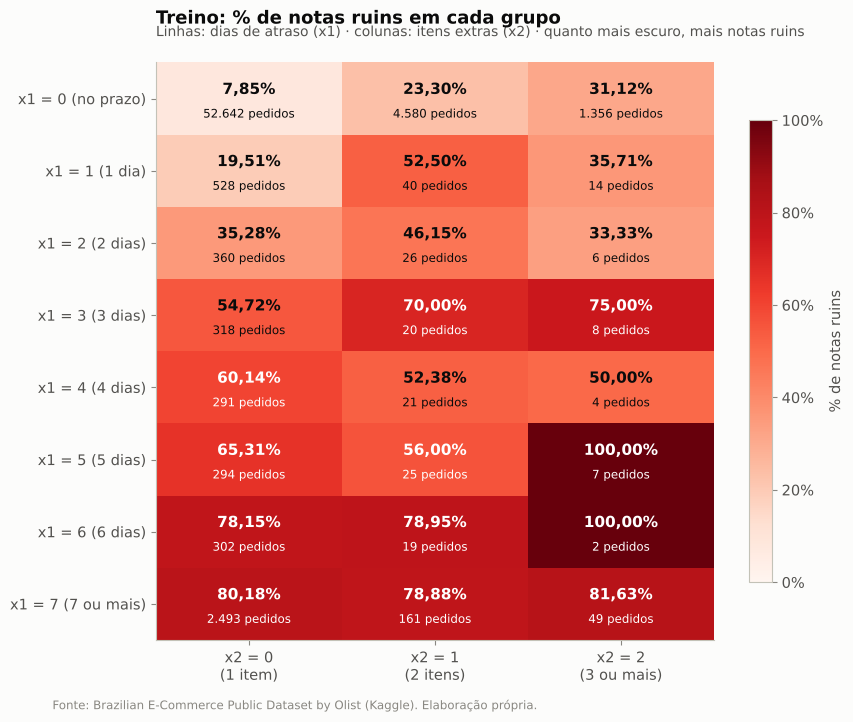

In [16]:
# ============================================================
# PASSO 3 · RESUMIR O TREINO EM GRUPOS (A TABELA QUE A REGRESSÃO USA)
# ============================================================
# Pedidos com o mesmo x1 e o mesmo x2 formam um grupo. Em cada grupo:
#   y (%) = notas ruins ÷ pedidos × 100


def montar_grupos(pedidos_parte):
    g = (pedidos_parte.groupby(["x1", "x2"])
         .agg(pedidos=("y", "size"), notas_ruins=("y", "sum"))
         .reset_index())
    g["y (%)"] = 100 * g["notas_ruins"] / g["pedidos"]
    return g


grupos_treino = montar_grupos(treino)
print(f"Treino: {br(len(treino))} pedidos resumidos em {len(grupos_treino)} grupos (8 situações de atraso × 3 de itens)")
print(f"Conferência: soma dos pedidos dos grupos = {br(grupos_treino['pedidos'].sum())} · "
      f"soma das notas ruins = {br(grupos_treino['notas_ruins'].sum())}")
display(grupos_treino.assign(x1=grupos_treino["x1"].astype(int), x2=grupos_treino["x2"].astype(int),
                             pedidos=grupos_treino["pedidos"].map(br), notas_ruins=grupos_treino["notas_ruins"].map(br),
                             **{"y (%)": grupos_treino["y (%)"].map(lambda v: br(v, 2))}))

# mapa de calor: % de notas ruins em cada grupo (com o nº de pedidos embaixo)
taxa = grupos_treino.pivot(index="x1", columns="x2", values="y (%)")
qtd = grupos_treino.pivot(index="x1", columns="x2", values="pedidos")
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(taxa.values, cmap="Reds", vmin=0, vmax=100, aspect="auto")
for i in range(taxa.shape[0]):
    for j in range(taxa.shape[1]):
        v = taxa.iloc[i, j]
        cor = "white" if v > 55 else viz.TINTA
        ax.text(j, i - 0.12, f"{br(v, 2)}%", ha="center", va="center", fontsize=11, weight="bold", color=cor)
        ax.text(j, i + 0.22, f"{br(qtd.iloc[i, j])} pedidos", ha="center", va="center", fontsize=8.5, color=cor)
ax.set_xticks(range(3), ["x2 = 0\n(1 item)", "x2 = 1\n(2 itens)", "x2 = 2\n(3 ou mais)"])
ax.set_yticks(range(8), ["x1 = 0 (no prazo)"] + [f"x1 = {k} ({k} dia{'s' if k > 1 else ''})" for k in range(1, 7)]
              + ["x1 = 7 (7 ou mais)"])
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, format=mtick.FuncFormatter(lambda v, _: f"{br(v)}%"), label="% de notas ruins")
viz.titulo(ax, "Treino: % de notas ruins em cada grupo",
           "Linhas: dias de atraso (x1) · colunas: itens extras (x2) · quanto mais escuro, mais notas ruins")
viz.fonte(fig)
viz.salvar_figura(fig, "05_grupos_treino")
plt.show()

**Leitura (passo 3):**

| Pergunta | Resultado | Interpretação |
|---|---|---|
| Onde está a maioria dos pedidos? | No prazo e com 1 item: 52.642 pedidos (83% do treino), com 7,85% de notas ruins | É o ponto de partida da equação |
| O que acontece quando atrasa (1 item)? | 19,5% (1 dia) → 35,3% (2) → 54,7% (3) → 60,1% (4) → 65,3% (5) → 78,2% (6) → 80,2% (7 ou mais) | Cada dia pesa, até estabilizar perto de 80% |
| E com mais itens, no prazo? | 7,85% (1 item) → 23,3% (2 itens) → 31,1% (3 ou mais) | Cada item a mais pesa, mesmo sem atraso |
| E os grupos pequenos? | Atraso com 2+ itens: de 2 a 161 pedidos por grupo, com % que pulam (ex.: 100% em 7 pedidos) | Com poucos pedidos, a % oscila muito. Por isso, na regressão, **cada grupo pesa pelo seu nº de pedidos** |

### Passo 4 · Correlação: cada variável × nota ruim (dispersão com reta)
Antes de juntar as duas variáveis, cada uma é conferida sozinha:
- **Painel 1:** só pedidos de **1 item**; x = dias de atraso; y = % de notas ruins.
- **Painel 2:** só pedidos **no prazo**; x = itens extras; y = % de notas ruins.

Cada ponto é um grupo do passo 3. O tamanho do ponto é o nº de pedidos, e é também o **peso** do ponto na reta: o grupo com 52 mil pedidos pesa mais do que um grupo com 300. A reta é a de **mínimos quadrados** e **r** é a correlação de Pearson (Aula 1 de Estatística), que vai de −1 a +1.

Painel 1 (atraso): y = 7,97 + 10,69 · x1 · r = 0,996 · r² = 0,991
Painel 2 (itens):  y = 7,94 + 13,31 · x2 · r = 0,989 · r² = 0,978
Conferência sem pesos (cada ponto vale igual, como na linha de tendência do Excel): r atraso = 0,978 · r itens = 0,983
Correlação entre x1 e x2 nos pedidos do treino: r = -0,018 (perto de zero: uma variável não 'rouba' o efeito da outra)


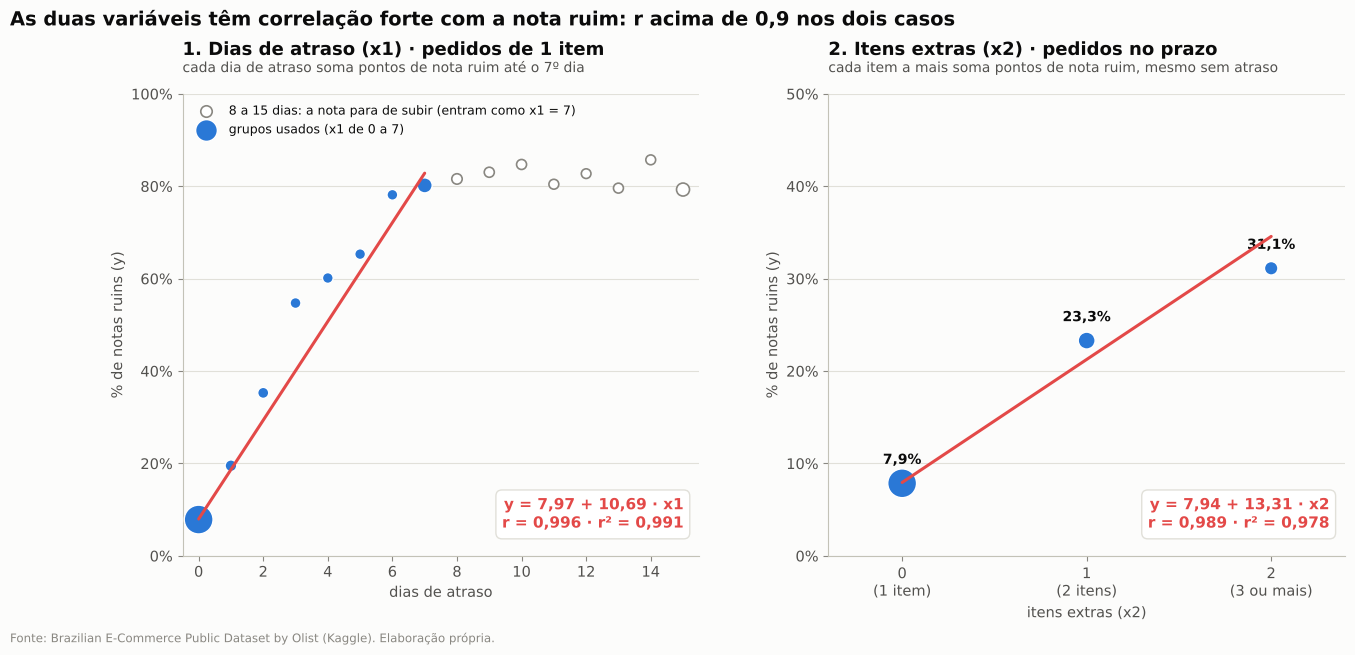

In [17]:
# ============================================================
# PASSO 4 · CORRELAÇÃO: CADA VARIÁVEL × % DE NOTAS RUINS (DISPERSÃO COM RETA)
# ============================================================
# Cada ponto é um grupo do treino; o tamanho do ponto é o nº de pedidos (e é o seu peso na reta).
# Painel 1: só pedidos de 1 item (x2 = 0), variando o atraso. Painel 2: só pedidos no prazo (x1 = 0), variando os itens.


def reta_ponderada(x, y, pesos):
    """Reta de mínimos quadrados em que cada ponto pesa pelo nº de pedidos; devolve a, b e r."""
    b, a = np.polyfit(x, y, 1, w=np.sqrt(pesos))          # polyfit pondera o erro: raiz do peso = peso no erro²
    mx, my = np.average(x, weights=pesos), np.average(y, weights=pesos)
    cov = np.average((x - mx) * (y - my), weights=pesos)
    r = cov / np.sqrt(np.average((x - mx) ** 2, weights=pesos) * np.average((y - my) ** 2, weights=pesos))
    return a, b, r


# dados de apoio: atraso dia a dia até 15 dias (para mostrar por que o x1 para em 7)
dia_a_dia = (treino[treino["x2"] == 0].assign(dias=treino["dias_atraso"].clip(lower=0, upper=15))
             .groupby("dias")["y"].agg(taxa="mean", pedidos="size"))
painel1 = grupos_treino[grupos_treino["x2"] == 0]
painel2 = grupos_treino[grupos_treino["x1"] == 0]
a_p1, b_p1, r_p1 = reta_ponderada(painel1["x1"], painel1["y (%)"], painel1["pedidos"])
a_p2, b_p2, r_p2 = reta_ponderada(painel2["x2"], painel2["y (%)"], painel2["pedidos"])
r_x1_x2 = treino["x1"].corr(treino["x2"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"wspace": 0.25})
tamanho = lambda n: 30 + 400 * np.sqrt(n / grupos_treino["pedidos"].max())
fora = dia_a_dia[dia_a_dia.index > 7]
ax1.scatter(fora.index, 100 * fora["taxa"], s=tamanho(fora["pedidos"]), facecolor="white", edgecolor=viz.TINTA_SUAVE,
            linewidth=1.2, zorder=3, label="8 a 15 dias: a nota para de subir (entram como x1 = 7)")
ax1.scatter(painel1["x1"], painel1["y (%)"], s=tamanho(painel1["pedidos"]), color=viz.DESTAQUE, edgecolor="white",
            zorder=4, label="grupos usados (x1 de 0 a 7)")
xs = np.linspace(0, 7, 20)
ax1.plot(xs, a_p1 + b_p1 * xs, color=viz.ALERTA, lw=2.2, zorder=5)
ax1.text(0.97, 0.05, f"y = {br(a_p1, 2)} + {br(b_p1, 2)} · x1\nr = {br(r_p1, 3)} · r² = {br(r_p1 ** 2, 3)}",
         transform=ax1.transAxes, ha="right", va="bottom", fontsize=11, weight="bold", color=viz.ALERTA,
         bbox=dict(facecolor="white", edgecolor=viz.GRADE, boxstyle="round,pad=0.4"))
ax1.set_xlim(-0.5, 15.5)
ax1.set_ylim(0, 100)
ax1.yaxis.set_major_formatter(viz.formato_pct())
ax1.set_xlabel("dias de atraso")
ax1.set_ylabel("% de notas ruins (y)")
ax1.legend(loc="upper left", frameon=False, fontsize=9)
viz.titulo(ax1, "1. Dias de atraso (x1) · pedidos de 1 item", "cada dia de atraso soma pontos de nota ruim até o 7º dia")

ax2.scatter(painel2["x2"], painel2["y (%)"], s=tamanho(painel2["pedidos"]), color=viz.DESTAQUE, edgecolor="white", zorder=4)
xs = np.linspace(0, 2, 20)
ax2.plot(xs, a_p2 + b_p2 * xs, color=viz.ALERTA, lw=2.2, zorder=5)
ax2.text(0.97, 0.05, f"y = {br(a_p2, 2)} + {br(b_p2, 2)} · x2\nr = {br(r_p2, 3)} · r² = {br(r_p2 ** 2, 3)}",
         transform=ax2.transAxes, ha="right", va="bottom", fontsize=11, weight="bold", color=viz.ALERTA,
         bbox=dict(facecolor="white", edgecolor=viz.GRADE, boxstyle="round,pad=0.4"))
for _, linha in painel2.iterrows():
    ax2.annotate(f"{br(linha['y (%)'], 1)}%", (linha["x2"], linha["y (%)"]), textcoords="offset points", xytext=(0, 14),
                 ha="center", fontsize=10, weight="bold")
ax2.set_xticks([0, 1, 2], ["0\n(1 item)", "1\n(2 itens)", "2\n(3 ou mais)"])
ax2.set_xlim(-0.4, 2.4)
ax2.set_ylim(0, 50)
ax2.yaxis.set_major_formatter(viz.formato_pct())
ax2.set_xlabel("itens extras (x2)")
ax2.set_ylabel("% de notas ruins (y)")
viz.titulo(ax2, "2. Itens extras (x2) · pedidos no prazo", "cada item a mais soma pontos de nota ruim, mesmo sem atraso")

fig.suptitle("As duas variáveis têm correlação forte com a nota ruim: r acima de 0,9 nos dois casos",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.02)
viz.fonte(fig)
viz.salvar_figura(fig, "05_correlacao_x1_x2")
plt.show()

print(f"Painel 1 (atraso): y = {br(a_p1, 2)} + {br(b_p1, 2)} · x1 · r = {br(r_p1, 3)} · r² = {br(r_p1 ** 2, 3)}")
print(f"Painel 2 (itens):  y = {br(a_p2, 2)} + {br(b_p2, 2)} · x2 · r = {br(r_p2, 3)} · r² = {br(r_p2 ** 2, 3)}")
print(f"Conferência sem pesos (cada ponto vale igual, como na linha de tendência do Excel): "
      f"r atraso = {br(np.corrcoef(painel1['x1'], painel1['y (%)'])[0, 1], 3)} · "
      f"r itens = {br(np.corrcoef(painel2['x2'], painel2['y (%)'])[0, 1], 3)}")
print(f"Correlação entre x1 e x2 nos pedidos do treino: r = {br(r_x1_x2, 3)} (perto de zero: uma variável não "
      f"'rouba' o efeito da outra)")

**Leitura (passo 4):**

| Pergunta | Resultado | Interpretação |
|---|---|---|
| x1 (atraso) tem correlação com y? | y = 7,97 + 10,69 · x1 · **r = 0,996** (r² = 0,991) | Correlação muito forte: cada dia de atraso soma cerca de 10,7 pontos de nota ruim |
| x2 (itens) tem correlação com y? | y = 7,94 + 13,31 · x2 · **r = 0,989** (r² = 0,978) | Muito forte: cada item extra soma cerca de 13,3 pontos. Ressalva: são só 3 pontos |
| E sem os pesos? | r = 0,978 (atraso) e 0,983 (itens), com cada ponto valendo igual | A correlação continua acima de 0,9: o resultado não depende dos pesos |
| A reta passa em todos os pontos? | Os grupos de 3 a 6 dias ficam acima da reta | A nota ruim sobe mais rápido nos primeiros dias; como esses grupos têm poucos pedidos, pesam pouco |
| E depois de 7 dias? | Os pontos vazados (8 a 15 dias) ficam entre 79% e 86% | A nota ruim para de subir; por isso x1 tem teto em 7 |
| x1 e x2 andam juntos? | r = −0,02 entre os dois | Praticamente independentes: na equação, um não "rouba" o efeito do outro |

### Passo 5 · Treino: calcular a equação (regressão linear múltipla)
| | |
|---|---|
| **Entra** | a tabela de 24 grupos do treino (passo 3): colunas x1, x2, y (%) e pedidos |
| **É feito** | regressão linear por **mínimos quadrados**: encontra a combinação de a, b1 e b2 que deixa a soma de (erro² × pedidos) a menor possível, em que erro = y real − y da equação |
| **Sai** | os três números da equação |

É a mesma ideia das retas do passo 4, agora com as duas variáveis ao mesmo tempo.

In [18]:
# ============================================================
# PASSO 5 · TREINO: CALCULAR A EQUAÇÃO (REGRESSÃO LINEAR MÚLTIPLA)
# ============================================================
# Entrada: a tabela de grupos do treino (passo 3)
#   X = colunas x1 e x2 · y = coluna "y (%)" · peso = nº de pedidos do grupo
# Método: mínimos quadrados → escolhe a, b1 e b2 que deixam a soma de (erro² × pedidos) a menor possível
# Saída: a equação  y (%) = a + b1 · x1 + b2 · x2

regressao = LinearRegression()
regressao.fit(grupos_treino[["x1", "x2"]], grupos_treino["y (%)"], sample_weight=grupos_treino["pedidos"])
a = regressao.intercept_
b1, b2 = regressao.coef_


def equacao(x1, x2):
    """Nota de risco (% de chance de nota ruim) dada pela equação do treino."""
    return a + b1 * x1 + b2 * x2


print(f"Coeficientes com mais casas: a = {a:.4f} · b1 = {b1:.4f} · b2 = {b2:.4f}")
print("EQUAÇÃO DO TREINO")
print(f"  y (%) = {br(a, 2)} + {br(b1, 2)} · x1 + {br(b2, 2)} · x2")
print(f"  a  = {br(a, 2)}  → ponto de partida: pedido no prazo (x1 = 0) e com 1 item (x2 = 0)")
print(f"  b1 = {br(b1, 2)}  → pontos a mais por dia de atraso (até 7 dias)")
print(f"  b2 = {br(b2, 2)} → pontos a mais por item extra (até 2 extras)")

# conferência: a mesma regressão feita pedido a pedido (63 mil linhas, y = 0 ou 100) dá os mesmos coeficientes
conferencia = LinearRegression().fit(treino[["x1", "x2"]], 100 * treino["y"])
print("\nCONFERÊNCIA: regressão feita direto nos pedidos do treino (sem agrupar)")
print(f"  y (%) = {br(conferencia.intercept_, 2)} + {br(conferencia.coef_[0], 2)} · x1 + {br(conferencia.coef_[1], 2)} · x2"
      "  → a mesma equação: a tabela de grupos é só um resumo dos pedidos")

# a equação em todas as combinações (o que ela devolve para cada grupo)
grade = pd.DataFrame([(x1, x2, equacao(x1, x2)) for x1 in range(8) for x2 in range(3)], columns=["x1", "x2", "risco"])
tabela_risco = grade.pivot(index="x1", columns="x2", values="risco")
tabela_risco.index = ["0 (no prazo)"] + [f"{k} dia{'s' if k > 1 else ''}" for k in range(1, 7)] + ["7 ou mais"]
tabela_risco.columns = ["1 item (x2 = 0)", "2 itens (x2 = 1)", "3 ou mais (x2 = 2)"]
tabela_risco.index.name = "dias de atraso (x1)"
print("\nNota de risco que a equação dá para cada combinação (%):")
display(tabela_risco.apply(lambda col: col.map(lambda v: f"{br(v, 1)}%")))

,1 item (x2 = 0),2 itens (x2 = 1),3 ou mais (x2 = 2)
dias de atraso (x1),,,
0 (no prazo),"8,1%","20,8%","33,5%"
1 dia,"18,6%","31,3%","44,0%"
2 dias,"29,1%","41,8%","54,5%"
3 dias,"39,6%","52,3%","65,0%"
4 dias,"50,1%","62,8%","75,5%"
5 dias,"60,6%","73,3%","86,0%"
6 dias,"71,0%","83,7%","96,4%"
7 ou mais,"81,5%","94,2%","106,9%"


Coeficientes com mais casas: a = 8.1434 · b1 = 10.4837 · b2 = 12.6973
EQUAÇÃO DO TREINO
  y (%) = 8,14 + 10,48 · x1 + 12,70 · x2
  a  = 8,14  → ponto de partida: pedido no prazo (x1 = 0) e com 1 item (x2 = 0)
  b1 = 10,48  → pontos a mais por dia de atraso (até 7 dias)
  b2 = 12,70 → pontos a mais por item extra (até 2 extras)

CONFERÊNCIA: regressão feita direto nos pedidos do treino (sem agrupar)
  y (%) = 8,14 + 10,48 · x1 + 12,70 · x2  → a mesma equação: a tabela de grupos é só um resumo dos pedidos

Nota de risco que a equação dá para cada combinação (%):


**Como ver a equação no gráfico:** com uma variável, a regressão é uma reta; com duas, é um **plano**.
- **Esquerda (3D):** o plano vermelho é a equação; os pontos são os 24 grupos do treino.
- **Direita:** o mesmo plano "visto de frente". Cada nº de itens vira uma reta. As três retas têm a **mesma inclinação** (b1, por dia de atraso) e ficam separadas pela **mesma distância** (b2, por item extra).

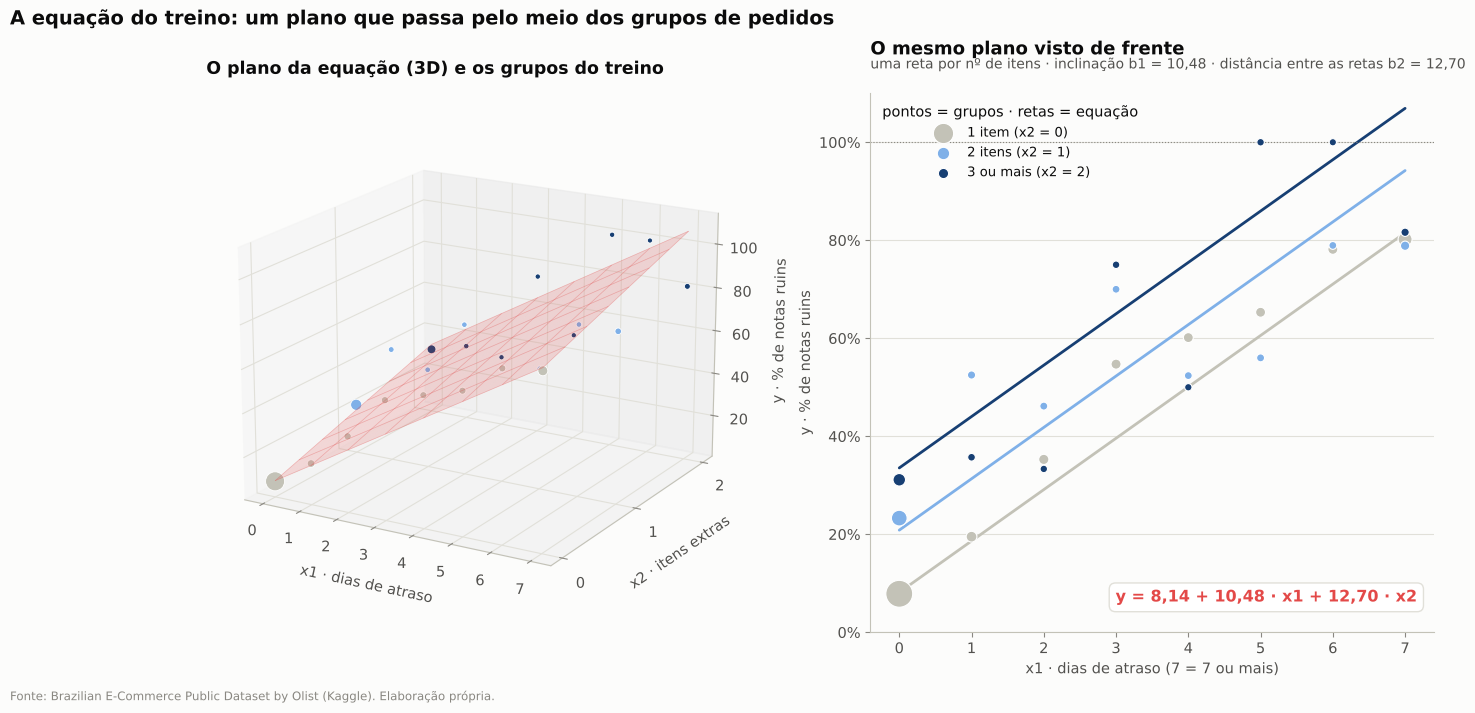

In [19]:
# ============================================================
# GRÁFICO DO PASSO 5 · A EQUAÇÃO É UM PLANO (3D) E, DE FRENTE, TRÊS RETAS PARALELAS
# ============================================================
cores_x2 = {0: viz.CONTEXTO, 1: "#7fb0e8", 2: "#173f73"}
rotulo_x2 = {0: "1 item (x2 = 0)", 1: "2 itens (x2 = 1)", 2: "3 ou mais (x2 = 2)"}
tamanho = lambda n: 25 + 350 * np.sqrt(n / grupos_treino["pedidos"].max())

fig = plt.figure(figsize=(16, 7))
# ---------- esquerda: o plano em 3D ----------
ax3 = fig.add_subplot(1, 2, 1, projection="3d")
gx, gy = np.meshgrid(np.linspace(0, 7, 15), np.linspace(0, 2, 15))
ax3.plot_surface(gx, gy, equacao(gx, gy), color=viz.ALERTA, alpha=0.18, edgecolor="none")
ax3.plot_wireframe(gx, gy, equacao(gx, gy), color=viz.ALERTA, alpha=0.35, linewidth=0.5, rstride=2, cstride=2)
for n, grupo in grupos_treino.groupby("x2"):
    ax3.scatter(grupo["x1"], grupo["x2"], grupo["y (%)"], s=tamanho(grupo["pedidos"]) * 0.5, color=cores_x2[n],
                edgecolor="white", linewidth=0.6, depthshade=False)
ax3.set_xlabel("x1 · dias de atraso", labelpad=8)
ax3.set_ylabel("x2 · itens extras", labelpad=8)
ax3.set_zlabel("y · % de notas ruins", labelpad=8)
ax3.set_yticks([0, 1, 2])
ax3.view_init(elev=18, azim=-60)
ax3.set_title("O plano da equação (3D) e os grupos do treino", loc="left", fontsize=12.5, weight="bold", color=viz.TINTA)

# ---------- direita: o mesmo plano visto de frente ----------
ax = fig.add_subplot(1, 2, 2)
xs = np.linspace(0, 7, 30)
for n, grupo in grupos_treino.groupby("x2"):
    ax.scatter(grupo["x1"], grupo["y (%)"], s=tamanho(grupo["pedidos"]), color=cores_x2[n], edgecolor="white",
               linewidth=0.8, zorder=3, label=rotulo_x2[n])
    ax.plot(xs, equacao(xs, n), color=cores_x2[n], lw=2, zorder=2)
ax.text(0.97, 0.05, f"y = {br(a, 2)} + {br(b1, 2)} · x1 + {br(b2, 2)} · x2", transform=ax.transAxes, ha="right",
        va="bottom", fontsize=11.5, weight="bold", color=viz.ALERTA,
        bbox=dict(facecolor="white", edgecolor=viz.GRADE, boxstyle="round,pad=0.4"))
ax.set_ylim(0, 110)
ax.set_xlim(-0.4, 7.4)
ax.axhline(100, color=viz.TINTA_SUAVE, lw=0.8, ls=":")
ax.yaxis.set_major_formatter(viz.formato_pct())
ax.set_xlabel("x1 · dias de atraso (7 = 7 ou mais)")
ax.set_ylabel("y · % de notas ruins")
ax.legend(title="pontos = grupos · retas = equação", loc="upper left", frameon=False, fontsize=9.5)
viz.titulo(ax, "O mesmo plano visto de frente", f"uma reta por nº de itens · inclinação b1 = {br(b1, 2)} · distância entre as retas b2 = {br(b2, 2)}")

fig.suptitle("A equação do treino: um plano que passa pelo meio dos grupos de pedidos",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.0)
viz.fonte(fig)
viz.salvar_figura(fig, "05_plano_equacao")
plt.show()

**Leitura (passo 5): a equação do treino**

$$y = 8{,}14 + 10{,}48 \cdot x_1 + 12{,}70 \cdot x_2$$

| Número | Valor | Em linguagem simples |
|---|---|---|
| **a** | 8,14 | Um pedido no prazo e com 1 item tem cerca de **8%** de chance de nota ruim |
| **b1** | 10,48 | Cada dia de atraso soma **10,5 pontos percentuais** (até 7 dias) |
| **b2** | 12,70 | Cada item extra soma **12,7 pontos** (até 3 itens ou mais) |

**Continhas com pedidos do passo 2:**

| Pedido | Conta | Nota de risco |
|---|---|---|
| No prazo, 1 item | 8,14 + 10,48 × 0 + 12,70 × 0 | **8,1%** |
| No prazo, 2 itens | 8,14 + 10,48 × 0 + 12,70 × 1 | **20,8%** |
| 3 dias de atraso, 1 item | 8,14 + 10,48 × 3 + 12,70 × 0 | **39,6%** |
| 5 dias de atraso, 2 itens | 8,14 + 10,48 × 5 + 12,70 × 1 | **73,2%** |
| 12 dias de atraso, 1 item (12 vira 7) | 8,14 + 10,48 × 7 + 12,70 × 0 | **81,5%** |

A tabela do código usa todas as casas decimais; diferenças de 0,1 vêm do arredondamento.

- **Conferência:** feita pedido a pedido (63.566 linhas, com y = 0 ou 100), a regressão dá **exatamente a mesma equação**. A tabela de grupos é só um resumo dos pedidos; nada se perde ao agrupar.
- **Limite:** a combinação "7 dias ou mais de atraso e 3 itens ou mais" dá 106,9%, acima de 100%. A reta não sabe que existe um teto. Isso atinge só 49 pedidos do treino; na prática, lê-se como "risco máximo".

### Passo 6 · Conferir o treino: previsto × real e R² (conta por conta)
| | |
|---|---|
| **Entra** | a equação (passo 5) e os 24 grupos do treino |
| **É feito** | para cada grupo: (1) **previsto** = a + b1 · x1 + b2 · x2; (2) **erro** = real − previsto; (3) erro² × pedidos; (4) (real − média)² × pedidos |
| **Sai** | o R² do treino |

$$R^2 = 1 - \frac{SQ_{res}}{SQ_{tot}} = 1 - \frac{\sum (\text{real} - \text{previsto})^2 \times \text{pedidos}}{\sum (\text{real} - \text{média})^2 \times \text{pedidos}}$$

- **SQres:** o erro que **sobra** depois de usar a equação (soma da coluna "erro² × pedidos").
- **SQtot:** o erro que haveria se a previsão de todo grupo fosse simplesmente a média (soma da coluna "(real − média)² × pedidos").
- **R² perto de 1:** a equação explica quase toda a variação; **perto de 0:** não explica nada.

In [20]:
# ============================================================
# PASSO 6 · CONFERIR O TREINO: PREVISTO × REAL E R² (CONTA POR CONTA)
# ============================================================
# R² = 1 − SQres ÷ SQtot
#   SQres = Σ (real − previsto)² × pedidos      → o erro que sobra depois da equação
#   SQtot = Σ (real − média)² × pedidos         → a variação total, se só usássemos a média


def conferir(grupos):
    """Aplica a equação aos grupos e calcula, coluna por coluna, os ingredientes do R²."""
    t = grupos.copy()
    t["previsto (%)"] = equacao(t["x1"], t["x2"])
    t["erro (real − previsto)"] = t["y (%)"] - t["previsto (%)"]
    media = np.average(t["y (%)"], weights=t["pedidos"])
    t["erro² × pedidos"] = t["erro (real − previsto)"] ** 2 * t["pedidos"]
    t["(real − média)² × pedidos"] = (t["y (%)"] - media) ** 2 * t["pedidos"]
    sq_res, sq_tot = t["erro² × pedidos"].sum(), t["(real − média)² × pedidos"].sum()
    return t, media, sq_res, sq_tot, 1 - sq_res / sq_tot


conf_treino, media_tr, sqres_tr, sqtot_tr, r2_treino = conferir(grupos_treino)


def mostrar(t):
    formatos = {"pedidos": br, "notas_ruins": br, "y (%)": lambda v: br(v, 2), "previsto (%)": lambda v: br(v, 2),
                "erro (real − previsto)": lambda v: f"{sinal(v)}{br(v, 2)}",
                "erro² × pedidos": lambda v: br(v, 0), "(real − média)² × pedidos": lambda v: br(v, 0)}
    saida = t.assign(x1=t["x1"].astype(int), x2=t["x2"].astype(int)).rename(columns={"y (%)": "y (%)"})
    for c, f in formatos.items():
        saida[c] = saida[c].map(f)
    display(saida.rename(columns={"y (%)": "real (%)", "notas_ruins": "notas ruins"}))


mostrar(conf_treino)
print("MEMORIAL DO R² (TREINO)")
print(f"  média ponderada de y = {br(media_tr, 2)}%")
print(f"  SQres = soma da coluna 'erro² × pedidos'           = {br(sqres_tr, 0)}")
print(f"  SQtot = soma da coluna '(real − média)² × pedidos' = {br(sqtot_tr, 0)}")
print(f"  R² = 1 − {br(sqres_tr, 0)} ÷ {br(sqtot_tr, 0)} = {br(r2_treino, 3)}  → a equação explica "
      f"{br(100 * r2_treino, 1)}% da variação da nota ruim entre os grupos · r = √R² = {br(np.sqrt(r2_treino), 3)}")

# para comparação: a mesma equação medida pedido a pedido (cada pedido vale 0 ou 100)
prev_pedidos = equacao(treino["x1"], treino["x2"])
r2_pedidos = 1 - ((100 * treino["y"] - prev_pedidos) ** 2).sum() / ((100 * treino["y"] - 100 * treino["y"].mean()) ** 2).sum()
print(f"\nPara comparação, pedido a pedido (y = 0 ou 100): R² = {br(r2_pedidos, 3)}. É baixo porque cada pedido é 'tudo ou nada' "
      "e a equação devolve uma chance; a % de notas ruins só existe num grupo de pedidos.")

,x1,x2,pedidos,notas ruins,real (%),previsto (%),erro (real − previsto),erro² × pedidos,(real − média)² × pedidos
0,0,0,52.642,4.134,"7,85","8,14","-0,29",4.438,1.996.989
1,0,1,4.580,1.067,"23,30","20,84","+2,46",27.633,394.825
2,0,2,1.356,422,"31,12","33,54","-2,42",7.921,396.913
3,1,0,528,103,"19,51","18,63","+0,88",409,15.945
4,1,1,40,21,"52,50","31,32","+21,18",17.936,59.252
5,1,2,14,5,"35,71","44,02","-8,31",966,6.594
6,2,0,360,127,"35,28","29,11","+6,17",13.691,162.801
7,2,1,26,12,"46,15","41,81","+4,35",491,26.860
8,2,2,6,2,"33,33","54,51","-21,17",2.690,2.240
9,3,0,318,174,"54,72","39,59","+15,12",72.723,526.887


MEMORIAL DO R² (TREINO)
  média ponderada de y = 14,01%
  SQres = soma da coluna 'erro² × pedidos'           = 295.173
  SQtot = soma da coluna '(real − média)² × pedidos' = 18.361.231
  R² = 1 − 295.173 ÷ 18.361.231 = 0,984  → a equação explica 98,4% da variação da nota ruim entre os grupos · r = √R² = 0,992

Para comparação, pedido a pedido (y = 0 ou 100): R² = 0,236. É baixo porque cada pedido é 'tudo ou nada' e a equação devolve uma chance; a % de notas ruins só existe num grupo de pedidos.


**Leitura (passo 6):**

| Pergunta | Resultado | Interpretação |
|---|---|---|
| Quanto a equação explica no treino? | R² = 1 − 295.173 ÷ 18.361.231 = **0,984** · r = 0,992 | Explica 98,4% da variação da nota ruim entre os grupos, **acima do critério de 0,70** |
| E nos grupos grandes? | No prazo e 1 item: real 7,85% × previsto 8,14% · 7+ dias e 1 item: real 80,18% × previsto 81,53% | Erro abaixo de 1,5 ponto onde estão quase todos os pedidos |
| Onde ela mais erra? | Nos grupos pequenos (ex.: 1 dia de atraso com 2 itens: real 52,5% × previsto 31,3%, só 40 pedidos) | O erro grande fica onde há poucos pedidos; como pesam pouco, quase não mexem no R² |

**Por que o R² é medido nos grupos, e não pedido a pedido:** cada pedido tem y = 0 ou 100, mas a equação devolve uma **chance** (por exemplo, 81,5%). Mesmo uma equação perfeita "erraria" cada pedido: como na moeda, ela acerta a proporção, não cada jogada. Por isso, pedido a pedido, o R² dessa mesma equação é de 0,236, e seria baixo para qualquer modelo de resultado sim/não. A relação é provada onde a porcentagem existe: nos grupos.

### Passo 7 · Teste: aplicar a mesma equação a pedidos novos
| | |
|---|---|
| **Entra** | os 31.994 pedidos do teste (abr a ago/2018) e a equação do treino, **sem mudar nenhum número** |
| **É feito** | (7.1) os pedidos do teste são resumidos nos mesmos grupos (mesmos x1 e x2); (7.2) em cada grupo, previsto = 8,14 + 10,48 · x1 + 12,70 · x2; (7.3) o previsto é comparado com a % real do teste, e o R² é calculado com as mesmas contas do passo 6 |
| **Sai** | o R² do teste: a prova de que a equação funciona fora dos dados em que foi calculada |

**Como ler o gráfico:** cada ponto é um grupo. No eixo x, o que a equação previu; no eixo y, o que aconteceu. Se a equação acerta, os pontos ficam sobre a diagonal tracejada (previsto = real).

,x1,x2,pedidos,notas ruins,real (%),previsto (%),erro (real − previsto),erro² × pedidos,(real − média)² × pedidos
0,0,0,27.532,1.900,"6,90","8,14","-1,24",42.492,333.234
1,0,1,2.336,535,"22,90","20,84","+2,06",9.930,366.305
2,0,2,736,189,"25,68","33,54","-7,86",45.453,172.274
3,1,0,216,27,"12,50","18,63","-6,13",8.109,971
4,1,1,16,4,"25,00","31,32","-6,32",640,3.420
5,1,2,5,1,"20,00","44,02","-24,02",2.885,463
6,2,0,135,39,"28,89","29,11","-0,22",7,46.248
7,2,1,7,3,"42,86","41,81","+1,05",8,7.383
8,2,2,2,1,"50,00","54,51","-4,51",41,3.139
9,3,0,142,54,"38,03","39,59","-1,57",348,108.547


Teste: 31.994 pedidos em 23 grupos · equação usada (do treino): y (%) = 8,14 + 10,48 · x1 + 12,70 · x2
MEMORIAL DO R² (TESTE)
  média ponderada de y = 10,38%
  R² = 1 − 222.431 ÷ 3.767.030 = 0,941 · r = √R² = 0,970


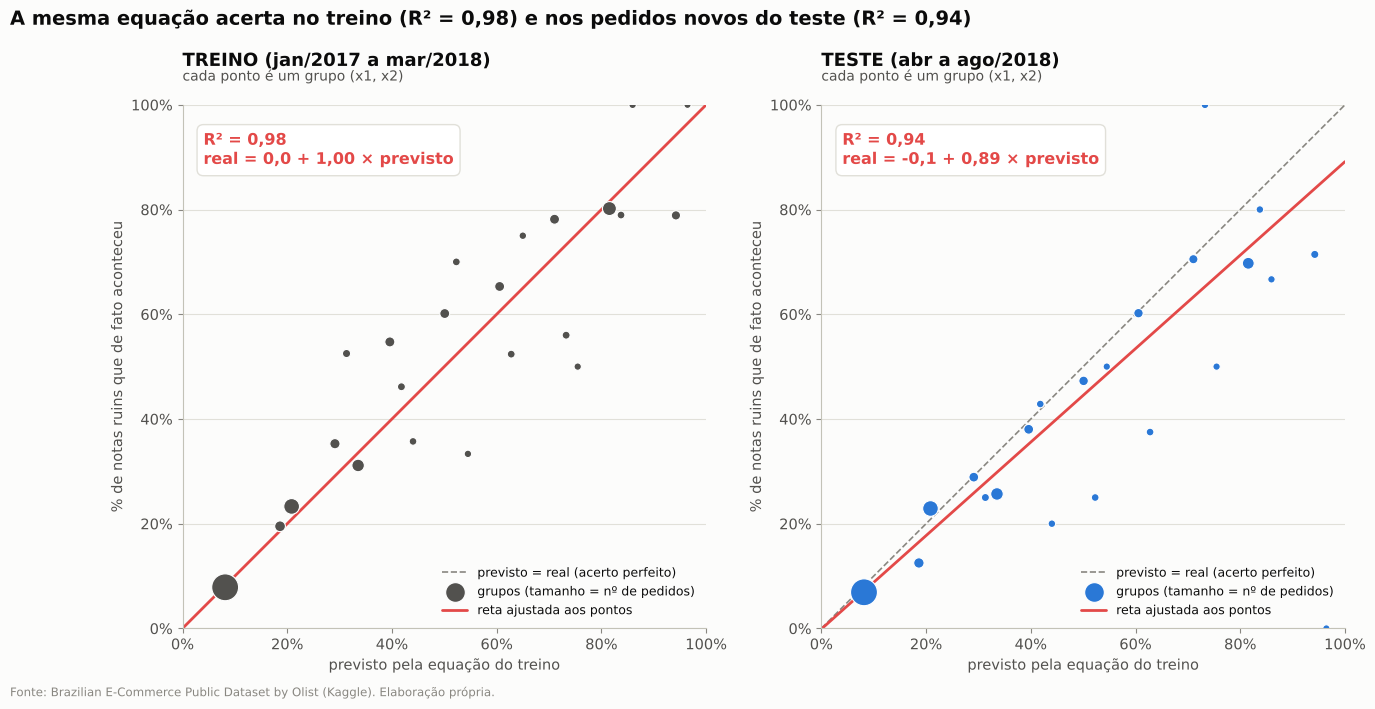

In [21]:
# ============================================================
# PASSO 7 · TESTE: APLICAR A MESMA EQUAÇÃO AOS PEDIDOS DE ABR–AGO/2018
# ============================================================
# 7.1 Os pedidos do teste são resumidos nos mesmos grupos (mesmos x1 e x2)
# 7.2 A equação do treino é aplicada SEM recalcular nada: a, b1 e b2 continuam os mesmos
# 7.3 Compara-se o previsto com o que de fato aconteceu e calcula-se o R² do teste

grupos_teste = montar_grupos(teste)
conf_teste, media_te, sqres_te, sqtot_te, r2_teste = conferir(grupos_teste)

print(f"Teste: {br(len(teste))} pedidos em {len(grupos_teste)} grupos · equação usada (do treino): "
      f"y (%) = {br(a, 2)} + {br(b1, 2)} · x1 + {br(b2, 2)} · x2")
mostrar(conf_teste)
print("MEMORIAL DO R² (TESTE)")
print(f"  média ponderada de y = {br(media_te, 2)}%")
print(f"  R² = 1 − {br(sqres_te, 0)} ÷ {br(sqtot_te, 0)} = {br(r2_teste, 3)} · r = √R² = {br(np.sqrt(r2_teste), 3)}")

# gráfico: previsto × real, treino e teste lado a lado
fig, eixos = plt.subplots(1, 2, figsize=(15, 6.8), gridspec_kw={"wspace": 0.22})
for ax, (nome, t, r2v, cor) in zip(eixos, [("TREINO (jan/2017 a mar/2018)", conf_treino, r2_treino, viz.TINTA_SECUNDARIA),
                                          ("TESTE (abr a ago/2018)", conf_teste, r2_teste, viz.DESTAQUE)]):
    ax.plot([0, 100], [0, 100], color=viz.TINTA_SUAVE, lw=1.2, ls="--", label="previsto = real (acerto perfeito)")
    ax.scatter(t["previsto (%)"], t["y (%)"], s=25 + 350 * np.sqrt(t["pedidos"] / t["pedidos"].max()), color=cor,
               edgecolor="white", linewidth=0.8, zorder=3, label="grupos (tamanho = nº de pedidos)")
    b_cal, a_cal = np.polyfit(t["previsto (%)"], t["y (%)"], 1, w=np.sqrt(t["pedidos"]))
    xs = np.linspace(0, 100, 20)
    ax.plot(xs, a_cal + b_cal * xs, color=viz.ALERTA, lw=2, label="reta ajustada aos pontos")
    ax.text(0.04, 0.95, f"R² = {br(r2v, 2)}\nreal = {br(a_cal, 1)} + {br(b_cal, 2)} × previsto", transform=ax.transAxes,
            va="top", fontsize=11.5, weight="bold", color=viz.ALERTA,
            bbox=dict(facecolor="white", edgecolor=viz.GRADE, boxstyle="round,pad=0.4"))
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.xaxis.set_major_formatter(viz.formato_pct())
    ax.yaxis.set_major_formatter(viz.formato_pct())
    ax.set_xlabel("previsto pela equação do treino")
    ax.set_ylabel("% de notas ruins que de fato aconteceu")
    ax.legend(loc="lower right", frameon=False, fontsize=9)
    viz.titulo(ax, nome, "cada ponto é um grupo (x1, x2)")
fig.suptitle(f"A mesma equação acerta no treino (R² = {br(r2_treino, 2)}) e nos pedidos novos do teste (R² = {br(r2_teste, 2)})",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.02)
viz.fonte(fig)
viz.salvar_figura(fig, "05_previsto_real")
plt.show()

**Leitura (passo 7):**

| Pergunta | Resultado | Interpretação |
|---|---|---|
| A equação acerta em pedidos novos? | R² do teste = 1 − 222.431 ÷ 3.767.030 = **0,941** · r = 0,970 | Sim: explica 94% da variação, **acima do critério de 0,70** |
| Caiu muito em relação ao treino? | R²: 0,984 (treino) → 0,941 (teste) | Queda pequena: a equação não "decorou" o treino (sem overfitting) |
| Onde ela erra? | Inclinação da reta previsto × real = 0,89; no maior grupo (no prazo, 1 item), real 6,90% × previsto 8,14% | A equação exagera um pouco. Em 2018, a nota ruim caiu até nos pedidos **sem atraso**, algo que atraso e itens não explicam |

### Passo 8 · Projeção mês a mês
| | |
|---|---|
| **Entra** | a equação do treino e todos os pedidos |
| **É feito** | cada pedido recebe a sua **nota de risco** (8,14 + 10,48 · x1 + 12,70 · x2); a projeção de cada mês é a **média das notas de risco** dos pedidos do mês |
| **Sai** | a % de notas ruins projetada × a real, mês a mês |

**Como ler o gráfico:** nos meses do treino (fundo branco), a linha vermelha mostra o **ajuste** da equação. Nos meses do teste (faixa azul), ela é uma **projeção**: a equação foi calculada antes desses meses e só recebeu o atraso e os itens de cada pedido.

**Exemplo de conta:** se num mês há 6.000 pedidos e a soma das notas de risco dá 66.000, a projeção é 66.000 ÷ 6.000 = 11,0% de notas ruins, ou 66.000 ÷ 100 = 660 notas ruins esperadas.

,pedidos,notas ruins reais,notas ruins projetadas,% real,% projetado,erro (p.p.)
abr/18,6.752,796,817,"11,79%","12,10%","+0,31"
mai/18,6.722,723,879,"10,76%","13,08%","+2,32"
jun/18,6.072,606,634,"9,98%","10,44%","+0,46"
jul/18,6.118,592,686,"9,68%","11,22%","+1,54"
ago/18,6.330,604,749,"9,54%","11,84%","+2,30"
total do teste,31.994,3.321,3.766,"10,38%","11,77%","+1,39"


Erro médio mensal no teste: 1,39 ponto percentual · total: projetadas 3.766 × reais 3.321 notas ruins (+13,4%)
Correlação mês a mês (20 meses, treino + teste): r = 0,959 · r² = 0,920


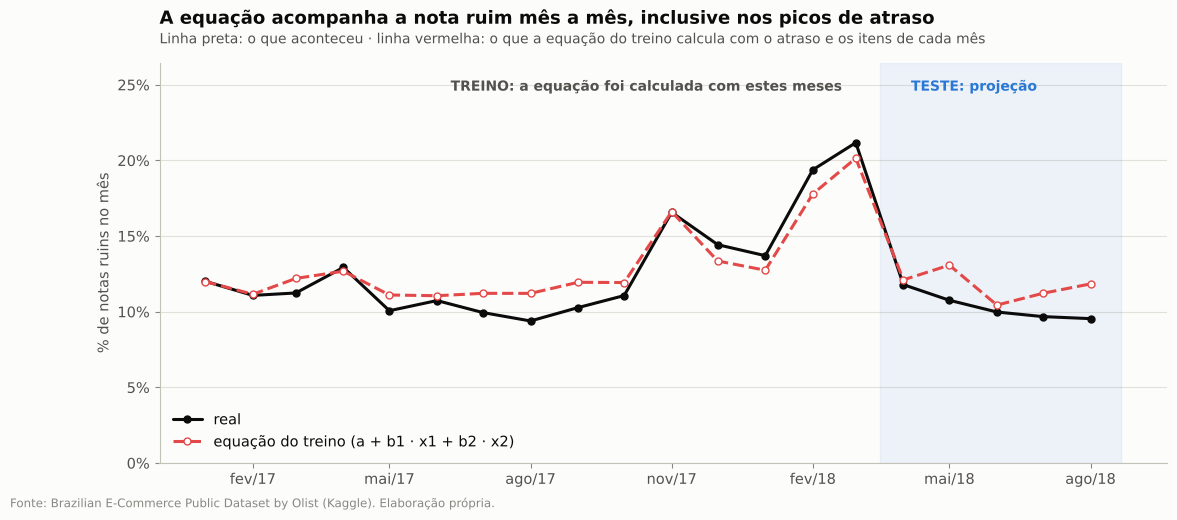

In [22]:
# ============================================================
# PASSO 8 · PROJEÇÃO MÊS A MÊS: A EQUAÇÃO DO TREINO PROJETADA NO PERÍODO DE TESTE
# ============================================================
# Cada pedido recebe a sua nota de risco: risco = a + b1 · x1 + b2 · x2
# Projeção do mês = média das notas de risco dos pedidos do mês (= notas ruins esperadas ÷ pedidos)

base["risco (%)"] = equacao(base["x1"], base["x2"])
mes_a_mes = base.groupby("mes").agg(pedidos=("y", "size"), notas_ruins=("y", "sum"),
                                     real=("y", "mean"), projetado=("risco (%)", "mean"))
mes_a_mes["real"] *= 100
mes_a_mes["notas ruins projetadas"] = mes_a_mes["projetado"] / 100 * mes_a_mes["pedidos"]
mes_a_mes["parte"] = np.where(mes_a_mes.index < CORTE, "treino", "teste")

fig, ax = plt.subplots(figsize=(13, 5.2))
ax.axvspan(CORTE - pd.Timedelta(days=15), mes_a_mes.index.max() + pd.Timedelta(days=20), color=viz.DESTAQUE, alpha=0.07)
ax.plot(mes_a_mes.index, mes_a_mes["real"], color=viz.TINTA, lw=2.2, marker="o", ms=5, label="real")
ax.plot(mes_a_mes.index, mes_a_mes["projetado"], color=viz.ALERTA, lw=2.2, ls="--", marker="o", ms=5, mfc="white",
        label="equação do treino (a + b1 · x1 + b2 · x2)")
topo = mes_a_mes[["real", "projetado"]].max().max() * 1.25
ax.set_ylim(0, topo)
ax.text(CORTE - pd.Timedelta(days=40), topo * 0.93, "TREINO: a equação foi calculada com estes meses", ha="right",
        fontsize=10, color=viz.TINTA_SECUNDARIA, weight="bold")
ax.text(CORTE + pd.Timedelta(days=5), topo * 0.93, "TESTE: projeção", ha="left", fontsize=10, color=viz.DESTAQUE, weight="bold")
ax.yaxis.set_major_formatter(viz.formato_pct())
ax.set_ylabel("% de notas ruins no mês")
viz.eixo_mensal(ax)
ax.legend(loc="lower left", frameon=False)
viz.titulo(ax, "A equação acompanha a nota ruim mês a mês, inclusive nos picos de atraso",
           "Linha preta: o que aconteceu · linha vermelha: o que a equação do treino calcula com o atraso e os itens de cada mês")
viz.fonte(fig)
viz.salvar_figura(fig, "05_projecao_mensal")
plt.show()

# tabela do período de teste
proj_teste = mes_a_mes[mes_a_mes["parte"] == "teste"].copy()
proj_teste["erro (p.p.)"] = proj_teste["projetado"] - proj_teste["real"]
total = pd.DataFrame({"pedidos": [proj_teste["pedidos"].sum()], "notas_ruins": [proj_teste["notas_ruins"].sum()],
                      "notas ruins projetadas": [proj_teste["notas ruins projetadas"].sum()]}, index=["total do teste"])
total["real"] = 100 * total["notas_ruins"] / total["pedidos"]
total["projetado"] = 100 * total["notas ruins projetadas"] / total["pedidos"]
total["erro (p.p.)"] = total["projetado"] - total["real"]
proj_teste.index = [f"{viz.MESES[m.month - 1]}/{str(m.year)[2:]}" for m in proj_teste.index]
tabela = pd.concat([proj_teste, total])[["pedidos", "notas_ruins", "notas ruins projetadas", "real", "projetado", "erro (p.p.)"]]
display(tabela.assign(pedidos=tabela["pedidos"].map(br), notas_ruins=tabela["notas_ruins"].map(br),
                      **{"notas ruins projetadas": tabela["notas ruins projetadas"].map(br),
                         "real": tabela["real"].map(lambda v: f"{br(v, 2)}%"),
                         "projetado": tabela["projetado"].map(lambda v: f"{br(v, 2)}%"),
                         "erro (p.p.)": tabela["erro (p.p.)"].map(lambda v: f"{sinal(v)}{br(v, 2)}")})
        .rename(columns={"notas_ruins": "notas ruins reais", "real": "% real", "projetado": "% projetado"}))
erro_medio = proj_teste["erro (p.p.)"].abs().mean()
print(f"Erro médio mensal no teste: {br(erro_medio, 2)} ponto percentual · total: projetadas "
      f"{br(total['notas ruins projetadas'].iloc[0])} × reais {br(total['notas_ruins'].iloc[0])} notas ruins "
      f"({sinal(total['erro (p.p.)'].iloc[0])}{br(100 * (total['notas ruins projetadas'].iloc[0] / total['notas_ruins'].iloc[0] - 1), 1)}%)")
r_mensal = np.corrcoef(mes_a_mes["projetado"], mes_a_mes["real"])[0, 1]
print(f"Correlação mês a mês (20 meses, treino + teste): r = {br(r_mensal, 3)} · r² = {br(r_mensal ** 2, 3)}")

**Leitura (passo 8):**

| Pergunta | Resultado | Interpretação |
|---|---|---|
| A equação acompanha os picos? | Sim: nov/2017 (Black Friday) e fev–mar/2018, os meses de mais atraso | A nota ruim sobe e desce junto com o atraso |
| Qual a correlação mês a mês? | r = 0,959 (r² = 0,92) nos 20 meses | Acima do critério de 0,70 |
| Quanto erra no teste? | Erro médio de 1,39 ponto por mês; total: 3.766 notas ruins projetadas × 3.321 reais (+13,4%) | A projeção fica acima do real. Cerca de 3/4 do excesso (342 de 445) vem dos pedidos no prazo com 1 item: 8,14% previstos × 6,90% reais |
| O que fazer com isso? | Recalcular a equação de tempos em tempos com os meses mais recentes | É o que se faz na implantação (passo 9) |

### Passo 9 · Usar a equação: a fila do atendimento
| | |
|---|---|
| **Entra** | os pedidos do teste, cada um com a sua nota de risco |
| **É feito** | os grupos são ordenados do maior para o menor risco (a **fila**); o atendimento começa pelo topo e desce até onde a capacidade permitir. Regra proposta: **contatar todo pedido com risco previsto de 20% ou mais** |
| **Sai** | quantos insatisfeitos (nota ruim real) o atendimento encontra, comparado com a regra simples "contatar só quem atrasou" |

Duas medidas (Storytelling, Aula 2, fase de avaliação do CRISP-DM):
- **Insatisfeitos encontrados (recall)** = notas ruins entre os contatados ÷ total de notas ruins.
- **Acerto por contato (precisão)** = notas ruins entre os contatados ÷ pedidos contatados.

,grupos,pedidos,notas ruins reais,% de notas ruins no bloco,% dos pedidos (acumulado),% dos insatisfeitos encontrados (acumulado)
risco previsto,,,,,,
70% ou mais,9,643,452,"70,3","2,0","13,6"
50% a 70%,5,226,117,"51,8","2,7","17,1"
30% a 50%,5,906,251,"27,7","5,5","24,7"
20% a 30%,2,2.471,574,"23,2","13,3","42,0"
abaixo de 20%,2,27.748,1.927,"6,9","100,0","100,0"


,quem é contatado,% dos pedidos contatados,insatisfeitos encontrados (recall),% de notas ruins entre os contatados (precisão)
Regra simples,só os pedidos atrasados (x1 > 0),"4,3%","21,0%","50,1%"
Equação da regressão,risco previsto de 20% ou mais,"13,3%","42,0%","32,8%"


A FILA DO TESTE, POR FAIXA DE RISCO PREVISTO (do topo para o fim):
MEMORIAL (equação): contatados = 4.246 pedidos (13,3% de 31.994) · insatisfeitos encontrados = 1.394 de 3.321 = 42,0% · precisão = 1.394 ÷ 4.246 = 32,8%


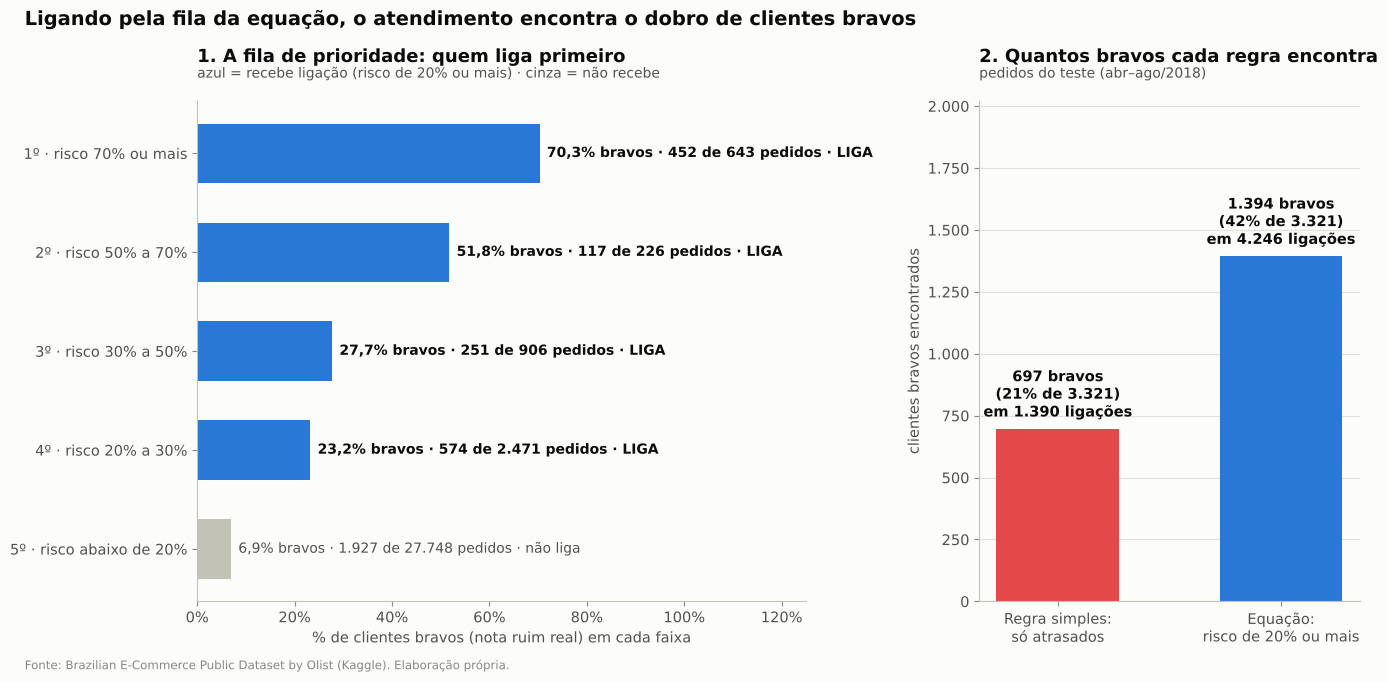

In [23]:
# ============================================================
# PASSO 9 · USAR A EQUAÇÃO: FILA DE PRIORIDADE DO ATENDIMENTO (PEDIDOS DO TESTE)
# ============================================================
# No dia da entrega, cada pedido recebe a nota de risco da equação. O atendimento começa pelos grupos de
# maior risco e desce a fila até onde a capacidade permitir. Conferimos com o que aconteceu de verdade.

fila = conf_teste[["x1", "x2", "previsto (%)", "pedidos", "notas_ruins"]].sort_values("previsto (%)", ascending=False)
fila["% dos pedidos (acumulado)"] = 100 * fila["pedidos"].cumsum() / fila["pedidos"].sum()
fila["% dos insatisfeitos encontrados (acumulado)"] = 100 * fila["notas_ruins"].cumsum() / fila["notas_ruins"].sum()
fila["% de notas ruins entre os contatados (acumulado)"] = 100 * fila["notas_ruins"].cumsum() / fila["pedidos"].cumsum()
# a fila resumida em faixas de risco (do topo para o fim)
faixas_risco = pd.cut(fila["previsto (%)"], [-np.inf, 20, 30, 50, 70, np.inf], right=False,
                      labels=["abaixo de 20%", "20% a 30%", "30% a 50%", "50% a 70%", "70% ou mais"])
blocos = (fila.groupby(faixas_risco, observed=True)
          .agg(grupos=("x1", "size"), pedidos=("pedidos", "sum"), notas_ruins=("notas_ruins", "sum"))
          .iloc[::-1])
blocos["% de notas ruins no bloco"] = 100 * blocos["notas_ruins"] / blocos["pedidos"]
blocos["% dos pedidos (acumulado)"] = 100 * blocos["pedidos"].cumsum() / blocos["pedidos"].sum()
blocos["% dos insatisfeitos encontrados (acumulado)"] = 100 * blocos["notas_ruins"].cumsum() / blocos["notas_ruins"].sum()
print("A FILA DO TESTE, POR FAIXA DE RISCO PREVISTO (do topo para o fim):")
display(blocos.assign(pedidos=blocos["pedidos"].map(br), notas_ruins=blocos["notas_ruins"].map(br),
                      **{c: blocos[c].map(lambda v: br(v, 1)) for c in blocos.columns if "%" in c})
        .rename(columns={"notas_ruins": "notas ruins reais"}).rename_axis("risco previsto"))

# regra de corte: contatar todo pedido com risco previsto de 20% ou mais
CORTE_RISCO = 20
contatados = fila[fila["previsto (%)"] >= CORTE_RISCO]
pct_contatados = 100 * contatados["pedidos"].sum() / fila["pedidos"].sum()
encontrados = contatados["notas_ruins"].sum()
recall_eq = 100 * encontrados / fila["notas_ruins"].sum()
precisao_eq = 100 * encontrados / contatados["pedidos"].sum()
# comparação: a regra simples "contatar só quem atrasou"
atrasados = fila[fila["x1"] > 0]
pct_regra = 100 * atrasados["pedidos"].sum() / fila["pedidos"].sum()
recall_regra = 100 * atrasados["notas_ruins"].sum() / fila["notas_ruins"].sum()
precisao_regra = 100 * atrasados["notas_ruins"].sum() / atrasados["pedidos"].sum()

comparacao_uso = pd.DataFrame({
    "quem é contatado": ["só os pedidos atrasados (x1 > 0)", f"risco previsto de {CORTE_RISCO}% ou mais"],
    "% dos pedidos contatados": [pct_regra, pct_contatados],
    "insatisfeitos encontrados (recall)": [recall_regra, recall_eq],
    "% de notas ruins entre os contatados (precisão)": [precisao_regra, precisao_eq],
}, index=["Regra simples", "Equação da regressão"])
display(comparacao_uso.assign(**{c: comparacao_uso[c].map(lambda v: f"{br(v, 1)}%") for c in comparacao_uso.columns[1:]}))
print(f"MEMORIAL (equação): contatados = {br(contatados['pedidos'].sum())} pedidos ({br(pct_contatados, 1)}% de "
      f"{br(fila['pedidos'].sum())}) · insatisfeitos encontrados = {br(encontrados)} de {br(fila['notas_ruins'].sum())} "
      f"= {br(recall_eq, 1)}% · precisão = {br(encontrados)} ÷ {br(contatados['pedidos'].sum())} = {br(precisao_eq, 1)}%")

# gráfico: barras de prioridade (1 = ligar primeiro) + comparação regra × equação
ordem_blocos = blocos.copy()
ordem_blocos["prioridade"] = range(1, len(ordem_blocos) + 1)
ligar = [faixa != "abaixo de 20%" for faixa in ordem_blocos.index]
cores = [viz.DESTAQUE if l else viz.CONTEXTO for l in ligar]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1.6, 1], "wspace": 0.35})
rotulos = [f"{p}º · risco {faixa}" for p, faixa in zip(ordem_blocos["prioridade"], ordem_blocos.index)]
posicoes = np.arange(len(ordem_blocos))[::-1]
ax1.barh(posicoes, ordem_blocos["% de notas ruins no bloco"], color=cores, height=0.6)
for y, (_, linha), l in zip(posicoes, ordem_blocos.iterrows(), ligar):
    ax1.text(linha["% de notas ruins no bloco"] + 1.5, y,
             f"{br(linha['% de notas ruins no bloco'], 1)}% bravos · {br(linha['notas_ruins'])} de {br(linha['pedidos'])} pedidos"
             f" · {'LIGA' if l else 'não liga'}", va="center", fontsize=10, weight="bold" if l else "normal",
             color=viz.TINTA if l else viz.TINTA_SECUNDARIA)
ax1.set_yticks(posicoes, rotulos)
ax1.set_xlim(0, 125)
ax1.xaxis.set_major_formatter(viz.formato_pct())
ax1.set_xlabel("% de clientes bravos (nota ruim real) em cada faixa")
ax1.grid(axis="y", visible=False)
viz.titulo(ax1, "1. A fila de prioridade: quem liga primeiro",
           f"azul = recebe ligação (risco de {CORTE_RISCO}% ou mais) · cinza = não recebe")

opcoes_barra = ["Regra simples:\nsó atrasados", f"Equação:\nrisco de {CORTE_RISCO}% ou mais"]
bravos = [atrasados["notas_ruins"].sum(), encontrados]
ligacoes = [atrasados["pedidos"].sum(), contatados["pedidos"].sum()]
barras = ax2.bar(opcoes_barra, bravos, color=[viz.ALERTA, viz.DESTAQUE], width=0.55)
for barra, n_bravos, n_lig, rec in zip(barras, bravos, ligacoes, [recall_regra, recall_eq]):
    ax2.text(barra.get_x() + barra.get_width() / 2, n_bravos + 30,
             f"{br(n_bravos)} bravos\n({br(rec, 0)}% de {br(fila['notas_ruins'].sum())})\nem {br(n_lig)} ligações",
             ha="center", va="bottom", fontsize=10.5, weight="bold")
ax2.set_ylim(0, max(bravos) * 1.45)
ax2.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: br(v)))
ax2.set_ylabel("clientes bravos encontrados")
ax2.grid(axis="x", visible=False)
viz.titulo(ax2, "2. Quantos bravos cada regra encontra", "pedidos do teste (abr–ago/2018)")

fig.suptitle("Ligando pela fila da equação, o atendimento encontra o dobro de clientes bravos",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.02)
viz.fonte(fig)
viz.salvar_figura(fig, "05_fila_atendimento")
plt.show()

**Leitura (P6):**

| Pergunta | Resultado | Interpretação |
|---|---|---|
| Quem entra na fila com 20% ou mais? | Todos os atrasados (menos "1 dia e 1 item") e os pedidos no prazo com 2 itens ou mais: 4.246 pedidos (13,3%) | A equação junta os dois problemas do Ato 2: atraso e pedido com vários itens |
| Quantos insatisfeitos encontra? | 1.394 de 3.321 = **42,0%** · precisão 32,8% | O **dobro** da regra do atraso |
| E a regra "só os atrasados"? | 4,3% contatados → 21,0% encontrados · precisão 50,1% | Acerta mais por contato, mas deixa de fora quase 4 de cada 5 insatisfeitos |
| E com o mesmo esforço da regra (4,3%)? | A fila da equação encontra cerca de 22% | Empata: os atrasados já estão no topo da fila. O ganho está em saber quem vem **depois** deles (os pedidos com vários itens) |

**Conclusão (P6):** sim. Uma regressão linear com só duas variáveis conhecidas no dia da entrega, **dias de atraso e nº de itens**, explica **98%** da variação da nota ruim entre os grupos no treino e **94%** nos pedidos novos do teste, acima do critério de 0,70. Na prática, a equação vira uma fila: contatando 13% dos pedidos, o atendimento encontra **42% dos insatisfeitos**, o dobro da regra do atraso.

**Implantação (fase 6 do CRISP-DM):**

| Etapa | Como fazer |
|---|---|
| 1. Calcular | No dia da entrega: risco = 8,14 + 10,48 × dias de atraso (até 7) + 12,70 × itens extras (até 2). Cabe numa fórmula de planilha |
| 2. Priorizar | Pedidos com risco de 20% ou mais vão para a fila do atendimento |
| 3. Monitorar | Todo mês: R² dos grupos, erro da projeção e % de insatisfeitos encontrados |
| 4. Recalcular | Quando o erro crescer (como em 2018, quando a nota ruim caiu mesmo sem atraso), refazer os passos 3 a 7 com os meses mais recentes |
| **Limite** | Parte da insatisfação vem do produto (defeito, expectativa), que não está nos dados. A equação prioriza grupos de pedidos; não adivinha a nota de cada pedido |

## 6. Como acompanhar: KPIs, metas e painel (P7)
Cada ação recomendada precisa de um indicador com **definição única** (`docs/metodologia.md`) e de uma meta **SMART**: específica, mensurável, alcançável, relevante e com prazo (Aula 2 de Fundamentos). Para os prazos, o acompanhamento segue a recomendação do case do pronto-socorro (Aula 4 de Estatística): **mediana** para o caso típico e **P90** para a cauda de esperas longas, em vez da média isolada.

**Linha de base:** jan/2017 a ago/2018. Os últimos meses não servem como referência porque os pedidos que ainda não tinham sido entregues ficam fora da base, o que faz o atraso recente parecer menor do que é. É um erro sistemático de coleta (Aula 1 de Estatística).

In [24]:
# ============================================================
# KPIs: LINHA DE BASE, METAS PROPOSTAS E ORIGEM DE CADA ANÁLISE
# ============================================================

ent_k = pedidos[pedidos["na_janela"] & pedidos["entregue"]].copy()
aval_k = ent_k[ent_k["review_score"].notna()]
nordeste = ent_k[ent_k["regiao_cliente"] == "Nordeste"]

# postagem depois do prazo-limite combinado com o vendedor (shipping_limit_date, base itens)
limite = itens.groupby("order_id")["shipping_limit_date"].max()
postados = ent_k[ent_k["order_delivered_carrier_date"].notna()].copy()
postados["postagem_tardia"] = postados["order_delivered_carrier_date"] > postados["order_id"].map(limite)

multi_prazo = aval_k[(aval_k["qtd_itens"] > 1) & ~aval_k["atrasado"].astype(bool)]
penetracao_ne = reg.loc["Nordeste", "pedidos por 100 mil hab."] / MESES_JANELA * 12

kpis = pd.DataFrame([
    ["Taxa de recompra em 180 dias", "clientes que voltam em 1 a 180 dias ÷ clientes da coorte",
     f"{br(100 * p_base, 1)}%", "Piloto com ~3.100 clientes por grupo; se aprovado, 3% em 12 meses",
     "mensal, por coorte", "04 · seção 2 (recompra em 180 dias) e 05 · seção 4 (piloto)"],
    ["% de entregas atrasadas", "pedidos atrasados ÷ pedidos entregues",
     f"{br(100 * ent_k['atrasado'].mean(), 1)}%", "5% em 12 meses, sem passar de 7% na Black Friday",
     "semanal", "03 · seção 3 (atraso ao longo do tempo, P4 e P5)"],
    ["Prazo de entrega: mediana e P90", "dias entre compra e entrega",
     f"{br(ent_k['dias_entrega'].median(), 1)} e {br(ent_k['dias_entrega'].quantile(0.9), 1)} dias",
     "P90 de até 20 dias em 12 meses", "semanal",
     "03 · seção 2 (jornada do pedido, P1 a P3); P90 calculado neste notebook"],
    ["Prazo mediano no Nordeste", "mediana dos dias de entrega no Nordeste",
     f"{br(nordeste['dias_entrega'].median(), 1)} dias", "12 dias em 12 meses", "mensal",
     "03 · seção 7 (regiões: prazo, atraso e frete, H4)"],
    ["Penetração no Nordeste", "pedidos por 100 mil habitantes, por ano",
     br(penetracao_ne, 1), "15 em 12 meses", "trimestral",
     "02 · seção 12 (onde estão os clientes, P14 a P16) e 05 · seção 3 (cenário C)"],
    ["% de avaliações ruins", "notas 1 e 2 ÷ pedidos avaliados",
     f"{br(100 * aval_k['avaliacao_ruim'].mean(), 1)}%", "11% em 6 meses", "mensal",
     "03 · seção 4 (o atraso derruba a nota?, H2) e 05 · seção 3 (cenários A e B)"],
    ["% de avaliações ruins com 2+ itens no prazo", "notas 1 e 2 ÷ pedidos de 2+ itens entregues no prazo",
     f"{br(100 * multi_prazo['avaliacao_ruim'].mean(), 1)}%", "15% em 6 meses", "mensal",
     "03 · seção 5 (o atraso não explica tudo, P10) e 05 · seção 3 (cenário B)"],
    ["% de postagens após o prazo-limite", "pedidos postados depois do limite ÷ pedidos postados",
     f"{br(100 * postados['postagem_tardia'].mean(), 1)}%", "4% em 6 meses", "semanal, por vendedor",
     "03 · seção 9 (vendedores: onde o atraso começa, P17 e P18)"],
], columns=["KPI", "fórmula", "linha de base (jan/17–ago/18)", "meta SMART (proposta)",
            "frequência", "onde foi analisado"]).set_index("KPI")

pd.set_option("display.max_colwidth", None)   # mostra os textos inteiros, sem cortar com "..."
display(kpis)

,fórmula,linha de base (jan/17–ago/18),meta SMART (proposta),frequência,onde foi analisado
KPI,,,,,
Taxa de recompra em 180 dias,clientes que voltam em 1 a 180 dias ÷ clientes da coorte,"1,9%","Piloto com ~3.100 clientes por grupo; se aprovado, 3% em 12 meses","mensal, por coorte",04 · seção 2 (recompra em 180 dias) e 05 · seção 4 (piloto)
% de entregas atrasadas,pedidos atrasados ÷ pedidos entregues,"6,8%","5% em 12 meses, sem passar de 7% na Black Friday",semanal,"03 · seção 3 (atraso ao longo do tempo, P4 e P5)"
Prazo de entrega: mediana e P90,dias entre compra e entrega,"10,2 e 23,1 dias",P90 de até 20 dias em 12 meses,semanal,"03 · seção 2 (jornada do pedido, P1 a P3); P90 calculado neste notebook"
Prazo mediano no Nordeste,mediana dos dias de entrega no Nordeste,"17,3 dias",12 dias em 12 meses,mensal,"03 · seção 7 (regiões: prazo, atraso e frete, H4)"
Penetração no Nordeste,"pedidos por 100 mil habitantes, por ano","9,8",15 em 12 meses,trimestral,"02 · seção 12 (onde estão os clientes, P14 a P16) e 05 · seção 3 (cenário C)"
% de avaliações ruins,notas 1 e 2 ÷ pedidos avaliados,"12,8%",11% em 6 meses,mensal,"03 · seção 4 (o atraso derruba a nota?, H2) e 05 · seção 3 (cenários A e B)"
% de avaliações ruins com 2+ itens no prazo,notas 1 e 2 ÷ pedidos de 2+ itens entregues no prazo,"24,6%",15% em 6 meses,mensal,"03 · seção 5 (o atraso não explica tudo, P10) e 05 · seção 3 (cenário B)"
% de postagens após o prazo-limite,pedidos postados depois do limite ÷ pedidos postados,"8,9%",4% em 6 meses,"semanal, por vendedor","03 · seção 9 (vendedores: onde o atraso começa, P17 e P18)"


O painel abaixo é um **protótipo** organizado pela **técnica do Z** (Aula 5 de Fundamentos): o olhar começa no canto superior esquerdo, onde ficam os KPIs críticos; passa pela evolução da receita no canto superior direito; desce para o detalhe por região no canto inferior esquerdo; e termina nas ações recomendadas, no canto inferior direito.

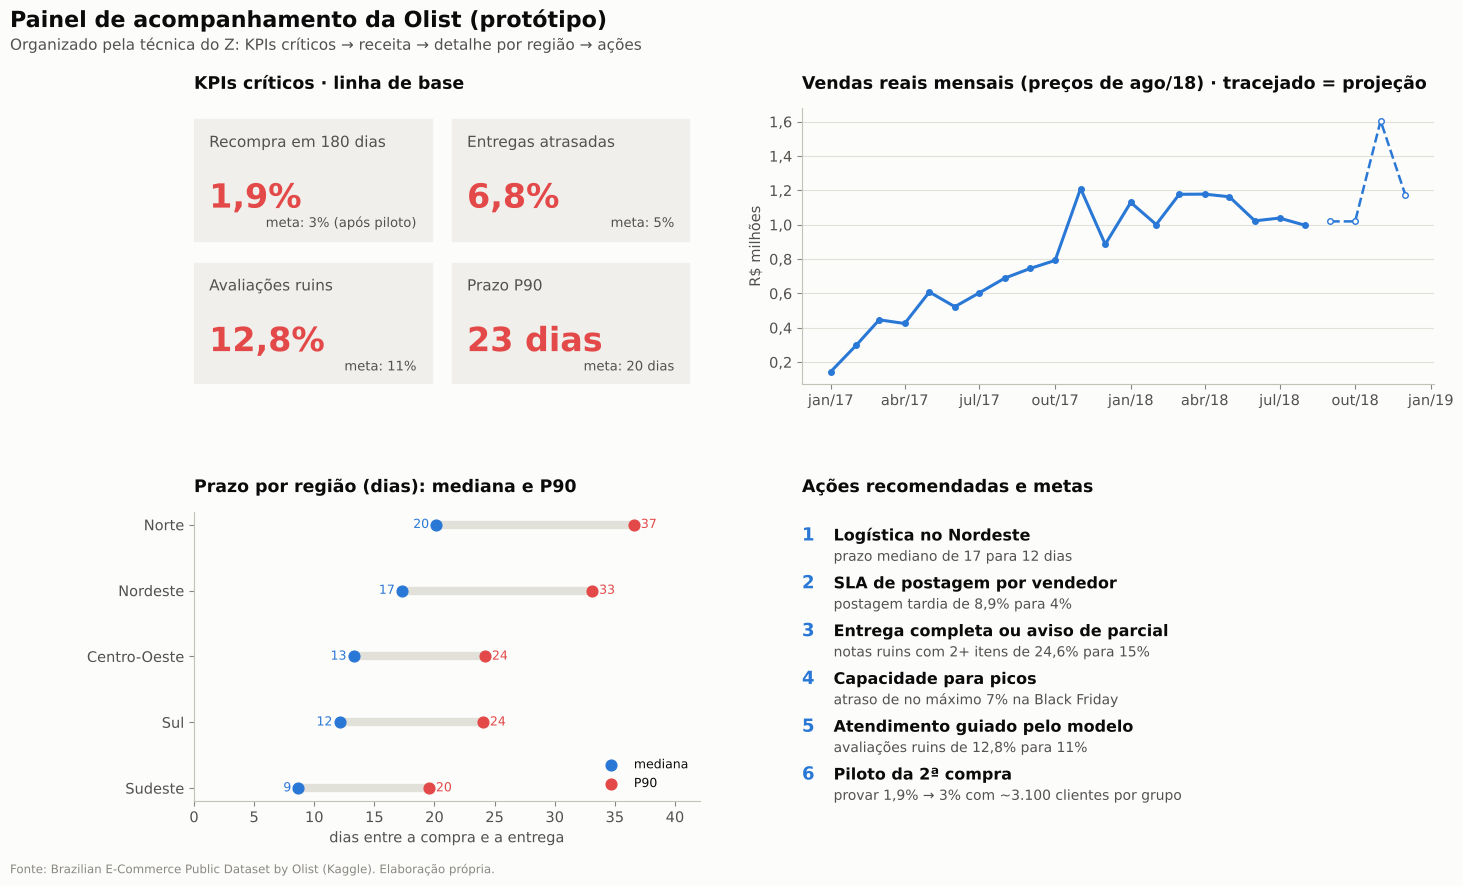

In [25]:
# ============================================================
# PAINEL DE ACOMPANHAMENTO (PROTÓTIPO) · TÉCNICA DO Z
# ============================================================

fig = plt.figure(figsize=(16, 9))
grade = fig.add_gridspec(2, 2, width_ratios=[1, 1.25], height_ratios=[1, 1.05], hspace=0.45, wspace=0.18)

# ---------- 1. canto superior esquerdo: KPIs críticos ----------
ax = fig.add_subplot(grade[0, 0])
ax.axis("off")
cartoes = [
    ("Recompra em 180 dias", f"{br(100 * p_base, 1)}%", "meta: 3% (após piloto)", viz.ALERTA),
    ("Entregas atrasadas", f"{br(100 * ent_k['atrasado'].mean(), 1)}%", "meta: 5%", viz.ALERTA),
    ("Avaliações ruins", f"{br(100 * aval_k['avaliacao_ruim'].mean(), 1)}%", "meta: 11%", viz.ALERTA),
    ("Prazo P90", f"{br(ent_k['dias_entrega'].quantile(0.9))} dias", "meta: 20 dias", viz.ALERTA),
]
for k, (nome, valor, meta, cor) in enumerate(cartoes):
    x0, y0 = (k % 2) * 0.51, 0.52 - (k // 2) * 0.52
    ax.add_patch(plt.Rectangle((x0, y0), 0.47, 0.44, transform=ax.transAxes, color="#f0efec"))
    ax.text(x0 + 0.03, y0 + 0.34, nome, transform=ax.transAxes, fontsize=11, color=viz.TINTA_SECUNDARIA)
    ax.text(x0 + 0.03, y0 + 0.12, valor, transform=ax.transAxes, fontsize=24, weight="bold", color=cor)
    ax.text(x0 + 0.44, y0 + 0.05, meta, transform=ax.transAxes, fontsize=9.5, ha="right", color=viz.TINTA_SECUNDARIA)
ax.set_title("KPIs críticos · linha de base", loc="left", fontsize=12.5, weight="bold", color=viz.TINTA)

# ---------- 2. canto superior direito: receita ----------
ax = fig.add_subplot(grade[0, 1])
ax.plot(mensal.index, mensal / 1e6, color=viz.DESTAQUE, lw=2.2, marker="o", ms=4)
ax.plot(proj.index, proj / 1e6, color=viz.DESTAQUE, lw=1.8, ls="--", marker="o", ms=4, mfc="white")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: br(x, 1)))
ax.set_ylabel("R\\$ milhões")
viz.eixo_mensal(ax)
ax.set_title("Vendas reais mensais (preços de ago/18) · tracejado = projeção", loc="left", fontsize=12.5,
             weight="bold", color=viz.TINTA)

# ---------- 3. canto inferior esquerdo: detalhe por região ----------
ax = fig.add_subplot(grade[1, 0])
prazo_reg = ent_k.groupby("regiao_cliente")["dias_entrega"].agg(mediana="median", p90=lambda s: s.quantile(0.9))
prazo_reg = prazo_reg.sort_values("mediana")
posicoes = np.arange(len(prazo_reg))
ax.hlines(posicoes, prazo_reg["mediana"], prazo_reg["p90"], color=viz.GRADE, lw=6)
ax.scatter(prazo_reg["mediana"], posicoes, color=viz.DESTAQUE, s=60, zorder=3, label="mediana")
ax.scatter(prazo_reg["p90"], posicoes, color=viz.ALERTA, s=60, zorder=3, label="P90")
for i, (med, p90) in enumerate(zip(prazo_reg["mediana"], prazo_reg["p90"])):
    ax.text(med - 0.6, i, br(med), ha="right", va="center", fontsize=9, color=viz.DESTAQUE)
    ax.text(p90 + 0.6, i, br(p90), ha="left", va="center", fontsize=9, color=viz.ALERTA)
ax.set_yticks(posicoes, prazo_reg.index)
ax.set_xlim(0, prazo_reg["p90"].max() * 1.15)
ax.set_xlabel("dias entre a compra e a entrega")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=False, fontsize=9)
ax.set_title("Prazo por região (dias): mediana e P90", loc="left", fontsize=12.5,
             weight="bold", color=viz.TINTA)

# ---------- 4. canto inferior direito: ações ----------
ax = fig.add_subplot(grade[1, 1])
ax.axis("off")
acoes = [
    ("1", "Logística no Nordeste", "prazo mediano de 17 para 12 dias"),
    ("2", "SLA de postagem por vendedor", "postagem tardia de 8,9% para 4%"),
    ("3", "Entrega completa ou aviso de parcial", "notas ruins com 2+ itens de 24,6% para 15%"),
    ("4", "Capacidade para picos", "atraso de no máximo 7% na Black Friday"),
    ("5", "Atendimento guiado pelo modelo", "avaliações ruins de 12,8% para 11%"),
    ("6", "Piloto da 2ª compra", "provar 1,9% → 3% com ~3.100 clientes por grupo"),
]
for k, (n, acao_txt, meta) in enumerate(acoes):
    y0 = 0.9 - k * 0.165
    ax.text(0.0, y0, n, transform=ax.transAxes, fontsize=13, weight="bold", color=viz.DESTAQUE)
    ax.text(0.05, y0, acao_txt, transform=ax.transAxes, fontsize=11.5, weight="bold", color=viz.TINTA)
    ax.text(0.05, y0 - 0.07, meta, transform=ax.transAxes, fontsize=10, color=viz.TINTA_SECUNDARIA)
ax.set_title("Ações recomendadas e metas", loc="left", fontsize=12.5, weight="bold", color=viz.TINTA)

fig.suptitle("Painel de acompanhamento da Olist (protótipo)", x=0.01, ha="left", fontsize=16,
             fontweight="bold", y=0.99)
fig.text(0.01, 0.945, "Organizado pela técnica do Z: KPIs críticos → receita → detalhe por região → ações",
         fontsize=11, color=viz.TINTA_SECUNDARIA)
viz.fonte(fig)
viz.salvar_figura(fig, "05_painel")
plt.show()

**Leitura (P7):**
- O painel responde, em uma tela, às três perguntas do investidor: **onde estamos** (KPIs críticos), **para onde vamos** (receita e projeção) e **o que está sendo feito** (ações e metas).
- O detalhe por região mostra por que a logística vem primeiro: no Norte e no Nordeste não só o prazo típico é maior, como a **cauda de esperas longas** (P90) passa de 33 dias, contra cerca de 20 no Sudeste.
- As metas são **propostas iniciais**, a calibrar com a operação; o painel deve ser revisado com quem vai usá-lo e atualizado conforme as prioridades mudarem (Aula 5 de Fundamentos).

**Conclusão (P7):** oito KPIs com definição única e meta SMART cobrem as três frentes do estudo (logística, satisfação e recompra) e permitem medir se cada ação está funcionando.

## 7. Fechamento: onde colocar o dinheiro (P8)

### 7.1 Recomendações

| # | Recomendação | Evidência | KPI | Meta SMART (proposta) |
|---|---|---|---|---|
| 1 | **Logística no Nordeste:** recrutar vendedores locais e negociar rotas para AL, MA, CE, BA e PE | Penetração 5 vezes menor que a do Sudeste; prazo mediano de 17,3 contra 8,7 dias; atraso de 13% contra 6%; frete de 22% contra 15% do valor | Prazo mediano no Nordeste; pedidos por 100 mil hab. por ano | Prazo de 17,3 para 12 dias e penetração de 9,8 para 15 em 12 meses |
| 2 | **SLA de postagem e ranking de vendedores**, com alerta e plano de ação para os 10% piores | Postagem depois do prazo-limite quadruplica o atraso (21% contra 5%); 10% dos vendedores causam 15% dos atrasos | % de postagens após o prazo-limite | De 8,9% para 4% em 6 meses |
| 3 | **Entrega completa ou aviso de entrega parcial**, com rastreio por item | Pedidos com 2+ itens têm 24,6% de notas ruins no prazo, contra 7,5% com 1 item; 43% das reclamações citam item faltando | % de avaliações ruins com 2+ itens no prazo | De 24,6% para 15% em 6 meses |
| 4 | **Plano de capacidade para picos:** Black Friday e fev–mar | O atraso sobe para 12% na Black Friday e 14–19% em fev–mar/2018 | % de entregas atrasadas no mês de pico | No máximo 7% em nov/2018 |
| 5 | **Atendimento proativo guiado pelo modelo de risco** | Contatando os 13% de maior risco pela equação (atraso + itens), o atendimento encontra 42% dos insatisfeitos; a regra do atraso encontra 21% | % de avaliações ruins; recall do modelo no grupo contatado | De 12,8% para 11% em 6 meses |
| 6 | **Piloto da 2ª compra** antes de um programa de retenção em escala, começando pelas categorias de reposição | Recompra de 1,9%; quem volta vale o dobro; categorias de reposição recompram até 2 vezes mais | Recompra em 180 dias | Piloto com ~3.100 clientes por grupo; se aprovado, de 1,9% para 3% em 12 meses |

### 7.2 Prioridade do investimento

| Ordem | Frente | Por quê |
|---|---|---|
| 1º | **Logística e experiência** (recomendações 1 a 4) | Reduz em cerca de 26% as avaliações ruins, protege a reputação e é **pré-condição** para crescer fora do Sudeste |
| 2º | **Expansão no Norte e Nordeste** (recomendação 1) | Maior alavanca de receita: cerca de R$ 1,9 mi por ano, 21% das vendas atuais |
| 3º | **Retenção validada por piloto** (recomendação 6) | Investimento pequeno e reversível; só escala se o teste provar o efeito |
| Contínuo | **Atendimento guiado pelo modelo** (recomendação 5) | Usa a capacidade do atendimento onde ela encontra mais clientes insatisfeitos |

### 7.3 Limitações
- **População acessível:** a base pública é uma amostra anonimizada de cerca de 100 mil pedidos, não a operação completa da Olist. Também não há custos, margens, investimento em marketing ou conversão: os valores são de vendas, não de lucro.
- **Causalidade:** as relações encontradas (atraso → nota, experiência → recompra) são observacionais. O piloto da seção 4 é a forma de confirmar o efeito de uma ação antes de escalar.
- **Período curto:** 20 meses limitam a projeção e a leitura da sazonalidade.
- **Meses finais incompletos:** pedidos ainda não entregues ficam fora da base, por isso as linhas de base usam a janela inteira.
- **Nota ordinal:** a nota de 1 a 5 é uma variável ordinal; por isso o estudo mede a satisfação pela **proporção** de notas 1 e 2.
- **Comentários:** a leitura dos temas das reclamações (notebook 03) é feita por palavras-chave e é aproximada.

### 7.4 Referências
**Dados**
- OLIST. *Brazilian E-Commerce Public Dataset by Olist*. Kaggle.
- BANCO CENTRAL DO BRASIL. Sistema Gerenciador de Séries Temporais (SGS), série 433: IPCA, variação mensal (fonte: IBGE).
- IBGE. SIDRA, tabela 6579: estimativas de população por UF, 2018.

**Metodologia** (bibliografia indicada nas aulas)
- BUSSAB, W. O.; MORETTIN, P. A. *Estatística Básica*. Saraiva.
- COCHRAN, W. G. *Sampling Techniques*. Wiley, 1977.
- KNAFLIC, C. *Storytelling com Dados*. Alta Books, 2019.
- MCKINNEY, W. *Python para Análise de Dados*. Novatec, 2018.
- PARMENTER, D. *Key Performance Indicators*. Wiley, 2015.
- PROVOST, F.; FAWCETT, T. *Data Science para Negócios*. Alta Books, 2016.
- TRIOLA, M. F. *Introdução à Estatística*. LTC.

**Documentos do projeto:** `docs/metodologia.md` (pergunta norteadora, hipóteses e KPIs), `docs/qualidade_dados.md` e `data/external/FONTES.md`.

### 7.5 Conclusão do estudo
**Pergunta norteadora:** *a Olist cresce de forma sustentável, e o que trava a satisfação e a recompra do cliente?*

| Pergunta | Resposta |
|---|---|
| A Olist cresce de forma sustentável? | **Ainda não.** Cresceu muito em 2017, mas parou em 2018: se nada mudar, entra em 2019 no mesmo patamar de cerca de R$ 1 mi por mês |
| O que trava a satisfação? | **O atraso** (raro, mas devastador) e **o pedido com vários itens** (insatisfação mesmo no prazo) |
| O que trava a recompra? | **A falta de um mecanismo de retenção.** O cliente sai satisfeito e mesmo assim não volta; a experiência ruim piora a recompra, mas não a explica |
| Onde colocar o dinheiro? | **Primeiro na logística**, que protege a reputação e destrava o Norte e o Nordeste; **depois na expansão regional**, a maior alavanca de receita; e **na retenção só depois de um piloto** que prove o efeito |

**Mensagem final:** a Olist tem demanda e alcance nacional, mas cresce apenas trazendo clientes novos e entrega pior justamente onde há mais espaço para crescer. Corrigir a logística e transformar o comprador de uma vez em cliente recorrente são as condições para que o crescimento volte e se sustente.